# Практическое занятие №1. Классификация. Дерево решений

**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Датасет **Iris** из `sklearn.datasets` - классический набор для классификации,
собранный Р. Фишером в 1936 году на побережье Финляндии. Каждая строка - один
цветок ириса, измеренный линейкой с точностью до 0,1 см: длина и ширина чашелистика
и лепестка. Всего **4 числовых признака** в сантиметрах и один целевой признак -
**вид**: `setosa`, `versicolor` или `virginica`.

Задача - **предсказать вид ириса по четырём измерениям цветка**, то есть задача
**многоклассовой классификации** с тремя равными по размеру классами.

Почему именно дерево решений:

* все признаки числовые, но дерево не требует их масштабировать и не ломается от
  разных единиц: ему достаточно сравнения «признак больше порога или нет»;
* дерево даёт **правила в явном виде**, поэтому модель можно не только обучить,
  но и прочитать глазами и пересказать на защите;
* на этом датасете видно главное свойство дерева: оно подбирает порог, который
  разделяет классы, - а значит, всю его силу можно проверить и описать словами;
* дерево легко переобучается, и на маленьком датасете это хорошо заметно, - то
  есть сразу видно, зачем нужны валидация и регуляризация.

Работа построена по шагам: данные - проверка и очистка - разведочный анализ -
подготовка - модель - обучение - оценка - выводы. Выбор модели делается по
валидации, тестовая выборка открывается один раз в разделе «Оценка».

**Честное предупреждение сразу.** Датасет крошечный (150 строк, 4 признака) и
почти идеально разделимым: на таких данных дерево почти всегда показывает
accuracy около 0,9-1,0. Это число **не доказывает**, что дерево хорошее. В
работе это показано прямо в числах: дерево, которому оставили только один
признак - ширину лепестка, - работает так же, а ручное правило из двух условий
`if` даёт на тесте ровно столько же, сколько обученная модель. Выводы в
разделе 8 об этом тоже.


In [1]:
# Зависимости.
%pip install -q numpy pandas scikit-learn matplotlib seaborn

# Проверка версий
import importlib

for _package in ("numpy", "pandas", "sklearn", "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.


numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты
import numpy as np                                       # численные массивы и случайные числа
import pandas as pd                                      # таблицы: срезы, статистика, группировки
import matplotlib.pyplot as plt                           # базовые графики
import seaborn as sns                                     # аккуратные распределения и тепловая карта

from sklearn.datasets import load_iris                    # официальный загрузчик датасета Iris
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree  # модель, её правила текстом и её схема
from sklearn.model_selection import (                     # разбиение выборки и оценка устойчивости модели
    train_test_split,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.dummy import DummyClassifier                 # базовая линия: всегда самый частый класс
from sklearn.feature_selection import mutual_info_classif # взаимная информация: вторая мера информативности
from sklearn.metrics import (                             # метрики качества классификации
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)


In [3]:
# Воспроизводимость: фиксируем генератор случайных чисел, иначе каждый запуск
# ноутбука давал бы немного разные результаты.
SEED = 42
np.random.seed(SEED)

# Графики должны попадать в вывод ноутбука как картинки - это делает inline-режим.
%matplotlib inline

# Русские названия признаков: в модели и в правилах дерева останутся
# английские имена из набора, а подписи на графиках делаем на русском.
FEATURE_RU = {
    "sepal length (cm)": "длина чашелистика",
    "sepal width (cm)": "ширина чашелистика",
    "petal length (cm)": "длина лепестка",
    "petal width (cm)": "ширина лепестка",
}

# Порядок классов задаём один раз: он используется и в цветах, и в отчётах,
# и в схеме дерева. Классы в наборе уже отсортированы по алфавиту.
CLASS_NAMES = ["setosa", "versicolor", "virginica"]
CLASS_COLORS = {"setosa": "#55A868", "versicolor": "#DD8452", "virginica": "#4C72B0"}

# Единый стиль оформления всех графиков ноутбука.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


## 1. Данные

**Iris** входит в `sklearn.datasets`, то есть физически лежит в пакете
`scikit-learn`. Загрузка идёт одной командой без сети и без ручного файла, и
поэтому ноутбук запускается одинаково на любой машине и в облаке.

Схема данных: **150 строк, 4 числовых признака, 3 класса**.

| Признак | Что измеряется | Единица |
|---|---|---|
| `sepal length (cm)` | длина чашелистика - верхнего лепестка цветка | сантиметры |
| `sepal width (cm)` | ширина чашелистика | сантиметры |
| `petal length (cm)` | длина лепестка - того, что окружает пестик | сантиметры |
| `petal width (cm)` | ширина лепестка | сантиметры |
| `species` | **цель**: вид ириса | setosa / versicolor / virginica |

Все значения измерены с точностью до 0,1 см, поэтому в каждом столбце
встречается не больше десятков различных чисел. Кодировать категории и
масштабировать признаки здесь не нужно, но проверять это мы всё равно обязаны:
по требованию к оформлению код проверки должен быть в работе в любом случае.


In [4]:
# датасет
iris = load_iris()

FEATURE_COLUMNS = list(iris.feature_names)
TARGET = "species"

# Собираем таблицу: матрица признаков и целевая переменная в одном DataFrame.
# Коды классов 0/1/2 сразу заменяем на настоящие названия видов - иначе в
# отчётах и на графиках вместо слов стояли бы цифры.
CLASS_ORDER = {index: name for index, name in enumerate(iris.target_names)}
raw = pd.DataFrame(iris.data, columns=FEATURE_COLUMNS)
raw[TARGET] = [CLASS_ORDER[index] for index in iris.target]

print(f"объект: {type(iris).__name__}, строк: {len(raw)}, признаков: {len(FEATURE_COLUMNS)}")
print(f"имена признаков: {FEATURE_COLUMNS}")
print(f"классы: {CLASS_NAMES}")
print("источник: пакет sklearn.datasets, сеть не требуется")
raw.head()


объект: Bunch, строк: 150, признаков: 4
имена признаков: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
классы: ['setosa', 'versicolor', 'virginica']
источник: пакет sklearn.datasets, сеть не требуется


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
# Красивое описание датасета
MEANING = pd.DataFrame({
    "признак": FEATURE_COLUMNS + [TARGET],
    "по-русски": list(FEATURE_RU.values()) + ["вид ириса"],
    "единица": ["сантиметры"] * 4 + ["вид"],
    "смысл": [
        "размер верхнего лепестка цветка",
        "поперечный размер верхнего лепестка",
        "размер нижнего лепестка у пестика",
        "поперечный размер нижнего лепестка",
        "целевая переменная: setosa, versicolor или virginica",
    ],
}).set_index("признак")

# Границы берём не из памяти, а из самих данных - так таблица не разойдётся
# с набором, даже если файл обновится. У целевой переменной границ нет: она
# не число, поэтому в её строке стоит прочерк, а не пустое место.
MEANING["минимум"] = [f"{value:.2f}" for value in raw[FEATURE_COLUMNS].min()] + ["-"]
MEANING["максимум"] = [f"{value:.2f}" for value in raw[FEATURE_COLUMNS].max()] + ["-"]
MEANING["свойств"] = list(raw[FEATURE_COLUMNS].nunique()) + [raw[TARGET].nunique()]
MEANING


,по-русски,единица,смысл,минимум,максимум,свойств
признак,,,,,,
sepal length (cm),длина чашелистика,сантиметры,размер верхнего лепестка цветка,4.30,7.90,35
sepal width (cm),ширина чашелистика,сантиметры,поперечный размер верхнего лепестка,2.00,4.40,23
petal length (cm),длина лепестка,сантиметры,размер нижнего лепестка у пестика,1.00,6.90,43
petal width (cm),ширина лепестка,сантиметры,поперечный размер нижнего лепестка,0.10,2.50,22
species,вид ириса,вид,"целевая переменная: setosa, versicolor или virginica",-,-,3


In [6]:
# Типы и сводная статистика
print(raw.dtypes)
print()
print(raw[FEATURE_COLUMNS].describe().round(3).T)


sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object

                   count   mean    std  min  25%   50%  75%  max
sepal length (cm)  150.0  5.843  0.828  4.3  5.1  5.80  6.4  7.9
sepal width (cm)   150.0  3.057  0.436  2.0  2.8  3.00  3.3  4.4
petal length (cm)  150.0  3.758  1.765  1.0  1.6  4.35  5.1  6.9
petal width (cm)   150.0  1.199  0.762  0.1  0.3  1.30  1.8  2.5


,цветов,"доля, %"
вид,,
setosa,50,33.33
versicolor,50,33.33
virginica,50,33.33


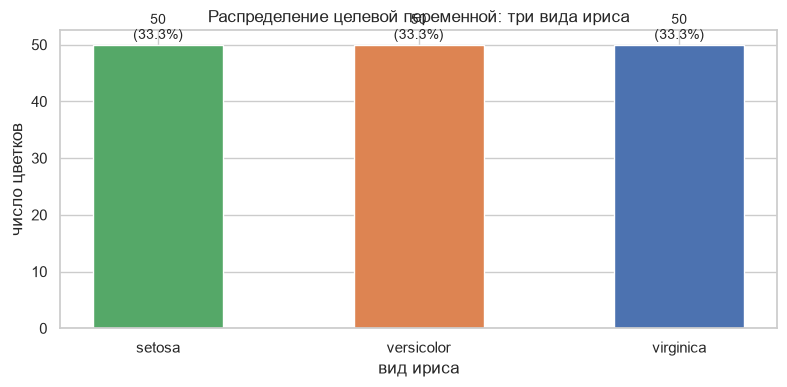

соотношение размеров классов: 1.00 к 1
базовая линия accuracy на равномерных классах равна 1/3 = 0.3333,
то есть модель обязана быть лучше трети, иначе она бессмысленна


In [7]:
# график целевой переменной
class_counts = raw[TARGET].value_counts().reindex(CLASS_NAMES)
class_shares = (raw[TARGET].value_counts(normalize=True).reindex(CLASS_NAMES) * 100).round(2)

class_table = pd.DataFrame({"цветов": class_counts, "доля, %": class_shares})
class_table.index.name = "вид"
display(class_table)

figure, axis = plt.subplots(figsize=(8, 4))
bars = axis.bar(class_table.index, class_table["цветов"],
                color=[CLASS_COLORS[name] for name in class_table.index], width=0.5)
axis.set_title("Распределение целевой переменной: три вида ириса")
axis.set_xlabel("вид ириса")
axis.set_ylabel("число цветков")
for bar, count, share in zip(bars, class_table["цветов"], class_table["доля, %"]):
    axis.text(bar.get_x() + bar.get_width() / 2, count + 1,
              f"{count}\n({share:.1f}%)", ha="center", fontsize=10)
figure.tight_layout()
plt.show()

print(f"соотношение размеров классов: {class_counts.max() / class_counts.min():.2f} к 1")
print("базовая линия accuracy на равномерных классах равна 1/3 = 0.3333,")
print("то есть модель обязана быть лучше трети, иначе она бессмысленна")


## 2. Проверка и очистка

Датасет из библиотеки приходит почти чистым, но по требованию к оформлению
проверки выполняются **в любом случае**: иначе неизвестно, что именно
проверялось. Ниже отдельно проверим пропуски, дубликаты и аномалии - и, если
что-то найдётся, покажем это прямо в работе.

Сразу скажем, что найдётся: в этом наборе есть **ровно один полный дубликат
строки**. Это не ошибка и не опечатка, а две записи одного и того же цветка,
попавшие в набор дважды. Строка повторяется один раз и на метку не влияет,
но оставить её - значит дважды дать одному объекту вес при обучении.


In [8]:
# Пропуски
missing = raw.isna().sum()
missing_frame = pd.DataFrame({"пропусков": missing, "доля": (missing / len(raw)).round(4)})
print(f"всего пропусков в таблице: {int(missing.sum())}")
print(f"строк хотя бы с одним пропуском: {int(raw.isna().any(axis=1).sum())}")
missing_frame


всего пропусков в таблице: 0
строк хотя бы с одним пропуском: 0


,пропусков,доля
sepal length (cm),0,0.0
sepal width (cm),0,0.0
petal length (cm),0,0.0
petal width (cm),0,0.0
species,0,0.0


In [9]:
# Стратегия на случай, если пропуски появятся: числовые признаки заполняем
# медианой - она устойчива к выбросам, в отличие от среднего, и не сдвигает
# распределение. Сейчас код ничего не меняет, потому что пропусков нет.
medians = raw[FEATURE_COLUMNS].median()

clean = raw.copy()
clean[FEATURE_COLUMNS] = clean[FEATURE_COLUMNS].fillna(medians)

print("пропусков до заполнения:", int(raw.isna().sum().sum()),
      "· после:", int(clean.isna().sum().sum()))
print("медианы числовых признаков (см):")
medians.round(2)


пропусков до заполнения: 0 · после: 0
медианы числовых признаков (см):


sepal length (cm)    5.80
sepal width (cm)     3.00
petal length (cm)    4.35
petal width (cm)     1.30
dtype: float64

In [10]:
# Дубликаты и противоречия разметки
repeated_rows = clean[clean.duplicated(keep=False)]
duplicated_positions = list(clean.index[clean.duplicated(keep=False)])

print(f"полных дубликатов (лишних копий): {int(clean.duplicated().sum())}")
print(f"строк, участвующих в повторе: {len(repeated_rows)}")
print(f"номера этих строк: {duplicated_positions}")
print()
print("эти строки целиком:")
display(repeated_rows)

# Те же номера в исходном наборе: так видно, что это настоящий дубль, а не
# результат нашей собственной обработки.
print("те же измерения в исходных 150 строках:")
display(raw.loc[repeated_rows.index])


полных дубликатов (лишних копий): 1
строк, участвующих в повторе: 2
номера этих строк: [101, 142]

эти строки целиком:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


те же измерения в исходных 150 строках:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


In [11]:
# Проверка на противоречия. Для Iris возможна только вторая ситуация: два
# цветка с одинаковыми четырьмя измерениями, но разными видами. Если бы такое
# нашлось, это была бы ошибка разметки, а не особенность данных.
labels_per_vector = clean.groupby(FEATURE_COLUMNS, observed=True)[TARGET].nunique()
contradictions = int((labels_per_vector > 1).sum())
feature_only_duplicates = int(clean.duplicated(subset=FEATURE_COLUMNS).sum())

print(f"повторов по набору признаков (без цели): {feature_only_duplicates}")
print(f"противоречий (одни признаки - разные метки): {contradictions}")

# Удаляем ровно одну лишнюю копию. drop_duplicates оставляет первую встречу,
# то есть из двух одинаковых строк остаётся одна - ровно то, что нужно.
before_rows = len(clean)
clean = clean.drop_duplicates().reset_index(drop=True)

print(f"строк было: {before_rows}, стало: {len(clean)}")
print("что удалили (вторая копия строки, номер в исходном наборе 142):")
display(clean[clean["petal width (cm)"] == 1.9].head(1))


повторов по набору признаков (без цели): 1
противоречий (одни признаки - разные метки): 0
строк было: 150, стало: 149
что удалили (вторая копия строки, номер в исходном наборе 142):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
101,5.8,2.7,5.1,1.9,virginica


In [12]:
# Аномалия первого типа - значения вне физически возможного диапазона.
# Цветок ирисы не бывает длиной 40 см: такие числа означали бы ошибку записи
# или другую единицу измерения. Диапазоны взяты с большим запасом.
LIMITS = {
    "sepal length (cm)": (2.0, 8.0),      # чашелистик от 2 до 8 см
    "sepal width (cm)": (0.5, 6.0),       # ширина чашелистика от 0,5 до 6 см
    "petal length (cm)": (0.5, 8.0),      # лепесток от 0,5 до 8 см
    "petal width (cm)": (0.1, 3.0),       # ширина лепестка от 0,1 до 3 см
}


def count_beyond_limits(frame):
    """Считает значения каждого признака, выпадающих из физического диапазона."""
    return pd.Series(
        {column: int(((frame[column] < low) | (frame[column] > high)).sum())
         for column, (low, high) in LIMITS.items()},
        name="нарушений диапазона",
    )


limits_report = count_beyond_limits(clean)
display(limits_report)
print(f"нарушений физического диапазона: {int(limits_report.sum())} из {len(clean)} строк")

# Отдельно проверяем, что все измерения кратны 0,1 см: это не аномалия, а
# следствие того, что цветы измерялись линейкой. Проверка нужна, чтобы честно
# сказать, где именно живёт точность модели.
rounding_ok = all(
    np.allclose(clean[column] * 10, np.round(clean[column] * 10))
    for column in FEATURE_COLUMNS
)
print(f"все измерения кратны 0,1 см: {rounding_ok}")
print("то есть 0,7 и 0,70 - это одно и то же число: у модели нет")
print("информации точнее, чем десятой доли сантиметра")


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Name: нарушений диапазона, dtype: int64

нарушений физического диапазона: 0 из 149 строк
все измерения кратны 0,1 см: True
то есть 0,7 и 0,70 - это одно и то же число: у модели нет
информации точнее, чем десятой доли сантиметра


In [13]:
# Аномалия второго типа - статистические выбросы. Пользуемся «забором Тьюки»:
# всё, что дальше Q1 - 1,5*IQR или Q3 + 1,5*IQR, считается выбросом. Метод
# не требует распределения и устойчив к форме данных.


def iqr_bounds(frame, factor=1.5):
    """Границы выбросов по межквартильному размаху: Q1 - f*IQR и Q3 + f*IQR."""
    lower_quartile = frame.quantile(0.25)
    upper_quartile = frame.quantile(0.75)
    interquartile_range = upper_quartile - lower_quartile
    return (lower_quartile - factor * interquartile_range,
            upper_quartile + factor * interquartile_range)


lower, upper = iqr_bounds(clean[FEATURE_COLUMNS])
outlier_mask = ((clean[FEATURE_COLUMNS] < lower) | (clean[FEATURE_COLUMNS] > upper))
outlier_rows = outlier_mask.any(axis=1)

print(f"строк с хотя бы одним выбросом: {int(outlier_rows.sum())} из {len(clean)} "
      f"({outlier_rows.mean():.1%})")
print()
print("выбросов по столбцам:")
print(outlier_mask.sum().to_frame("выбросов"))
print()
print("границы «забора Тьюки», см:")
print(pd.DataFrame({"нижняя": lower.round(3), "верхняя": upper.round(3)}))


строк с хотя бы одним выбросом: 4 из 149 (2.7%)

выбросов по столбцам:
                   выбросов
sepal length (cm)         0
sepal width (cm)          4
petal length (cm)         0
petal width (cm)          0

границы «забора Тьюки», см:
                   нижняя  верхняя
sepal length (cm)    3.15     8.35
sepal width (cm)     2.05     4.05
petal length (cm)   -3.65    10.35
petal width (cm)    -1.95     4.05


### Что делаем с выбросами

Выбросы здесь - **не битые записи**, а самые крупные и самые мелкие цветки в
выборке. Удалять их нельзя: длинный лепесток - это ровно тот признак, по
которому отличается `virginica`, и именно на правом хвосте распределения
дерево принимает самые важные решения.

Поэтому выбросы **оставляем**. Проверка на физический диапазон показала, что
ни одно значение не выходит за пределы разумного, - а значит, очистка сводится
к одному действию: удалить найденный дубликат. Ниже это и делаем.


In [14]:
# Посмотрим, кто эти выбросы: обычно это самые крупные цветки, и их удаление
# испортило бы распределение класса.
extreme_rows = clean.loc[outlier_rows, FEATURE_COLUMNS + [TARGET]].sort_values(
    "petal length (cm)", ascending=False)
print("строки-выбросы, отсортированные по длине лепестка:")
display(extreme_rows)
print(f"классы среди выбросов: {sorted(clean.loc[outlier_rows, TARGET].unique())}")


строки-выбросы, отсортированные по длине лепестка:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
60,5.0,2.0,3.5,1.0,versicolor
15,5.7,4.4,1.5,0.4,setosa
32,5.2,4.1,1.5,0.1,setosa
33,5.5,4.2,1.4,0.2,setosa


классы среди выбросов: ['setosa', 'versicolor']


In [15]:
# Итог очистки: из 150 строк осталось 149. Удалена ровно одна строка - вторая
# копия цветка с измерениями 5,8 / 2,7 / 5,1 / 1,9 см.
print(f"строк было: {len(raw)} · строк после очистки: {len(clean)}")
print(f"удалено дубликатов: {before_rows - len(clean)}")
print(f"признаков: {clean.shape[1] - 1} числовых, категориальных: 0")
print(f"пропусков: {int(clean.isna().sum().sum())} · "
      f"противоречий разметки: {contradictions}")
print(f"нарушений физического диапазона: {int(limits_report.sum())}")
print(f"строк-выбросов оставлено осознанно: {int(outlier_rows.sum())}")

# Баланс классов после удаления дубля: он нарушился на одну строку, и это надо
# видеть, а не замечать на графике метрик.
print()
print(clean[TARGET].value_counts().reindex(CLASS_NAMES).to_frame("цветков").T)
clean.head()


строк было: 150 · строк после очистки: 149


удалено дубликатов: 1
признаков: 4 числовых, категориальных: 0
пропусков: 0 · противоречий разметки: 0
нарушений физического диапазона: 0
строк-выбросов оставлено осознанно: 4

species  setosa  versicolor  virginica
цветков      50          50         49


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Разведочный анализ

Четыре числовых признака и три класса - набор настолько маленький, что его
можно разобрать руками. Именно так и поступим:

* **распределения** каждого признака с разбивкой по видам;
* **ящики с усами** по классам: видно, где классы расходятся, а где накрывают
  друг друга;
* **точка, ради которой затевается вся работа**: один порог по ширине лепестка
  отделяет `setosa` от двух других видов без единой ошибки;
* **матрица корреляций** и **взаимная информация** - две разные меры связи
  признака с видом.


### 3.1 Распределения признаков

Два признака - длина и ширина лепестка - распределены по классам почти
без наложений: у `setosa` они маленькие, у `virginica` большие. Два признака
чашелистика распределены гораздо хуже: `setosa` по длине ещё отличается, а по
ширине вообще перемешан с остальными видами. Это уже видный заранее вывод:
полезны будут лепестки, а не чашелистики.


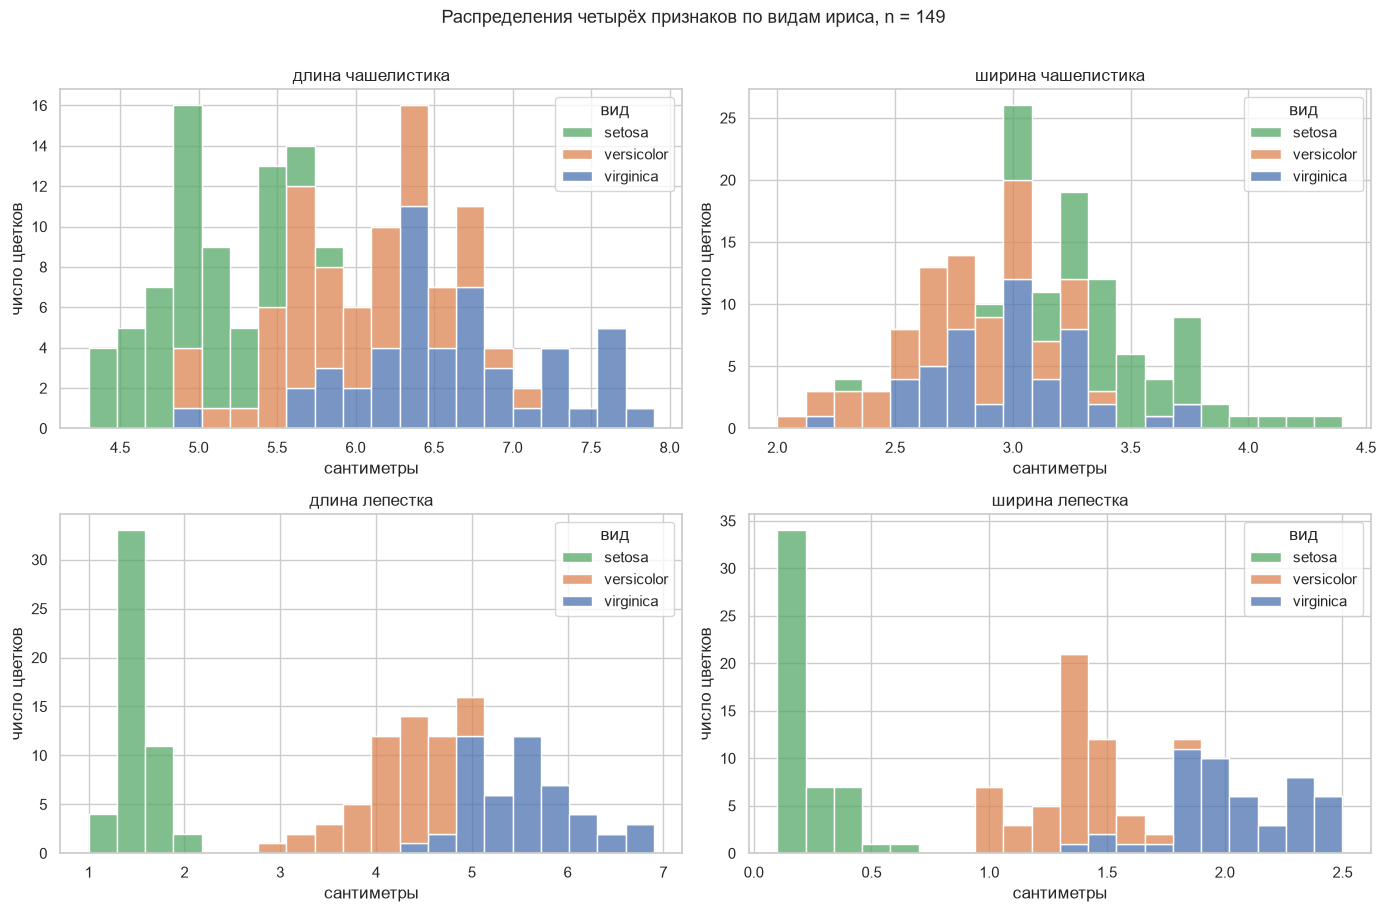

In [16]:
# Распределения всех четырёх признаков с разбивкой по видам. Стопки цветов
# показывают, насколько «чисто» делятся наблюдения: если столбики одного цвета
# стоят рядом и не перемешиваются - разделить классы легко.
figure, axes = plt.subplots(2, 2, figsize=(14, 9))

for axis, column in zip(axes.ravel(), FEATURE_COLUMNS):
    sns.histplot(data=clean, x=column, hue=TARGET, hue_order=CLASS_NAMES,
                 multiple="stack", palette=CLASS_COLORS, bins=20, ax=axis)
    axis.set_title(FEATURE_RU[column])
    axis.set_xlabel("сантиметры")
    axis.set_ylabel("число цветков")
    axis.get_legend().set_title("вид")

figure.suptitle("Распределения четырёх признаков по видам ириса, n = %d" % len(clean), y=1.01)
figure.tight_layout()
plt.show()


### 3.2 Ящики с усами: где классы расходятся, а где нет

Главный вопрос разведки: **какие признаки вообще различают виды?**

* по **длине лепестка** и **ширине лепестка** ящики трёх видов стоят друг за
  другом почти без перекрытия - это сильные признаки;
* по **длине чашелистика** `setosa` заметно короче, но `versicolor` и
  `virginica` перекрываются;
* по **ширине чашелистика** ящики лежат друг на друге - признак почти бесполезен.

Расстояние между ящиками лепестков настолько велико, что дерево, вообще не
умеющее работать с кривыми, справится с такой задачей без труда. Это стоит
запомнить: хороший результат здесь не заслуга модели, а свойство данных.


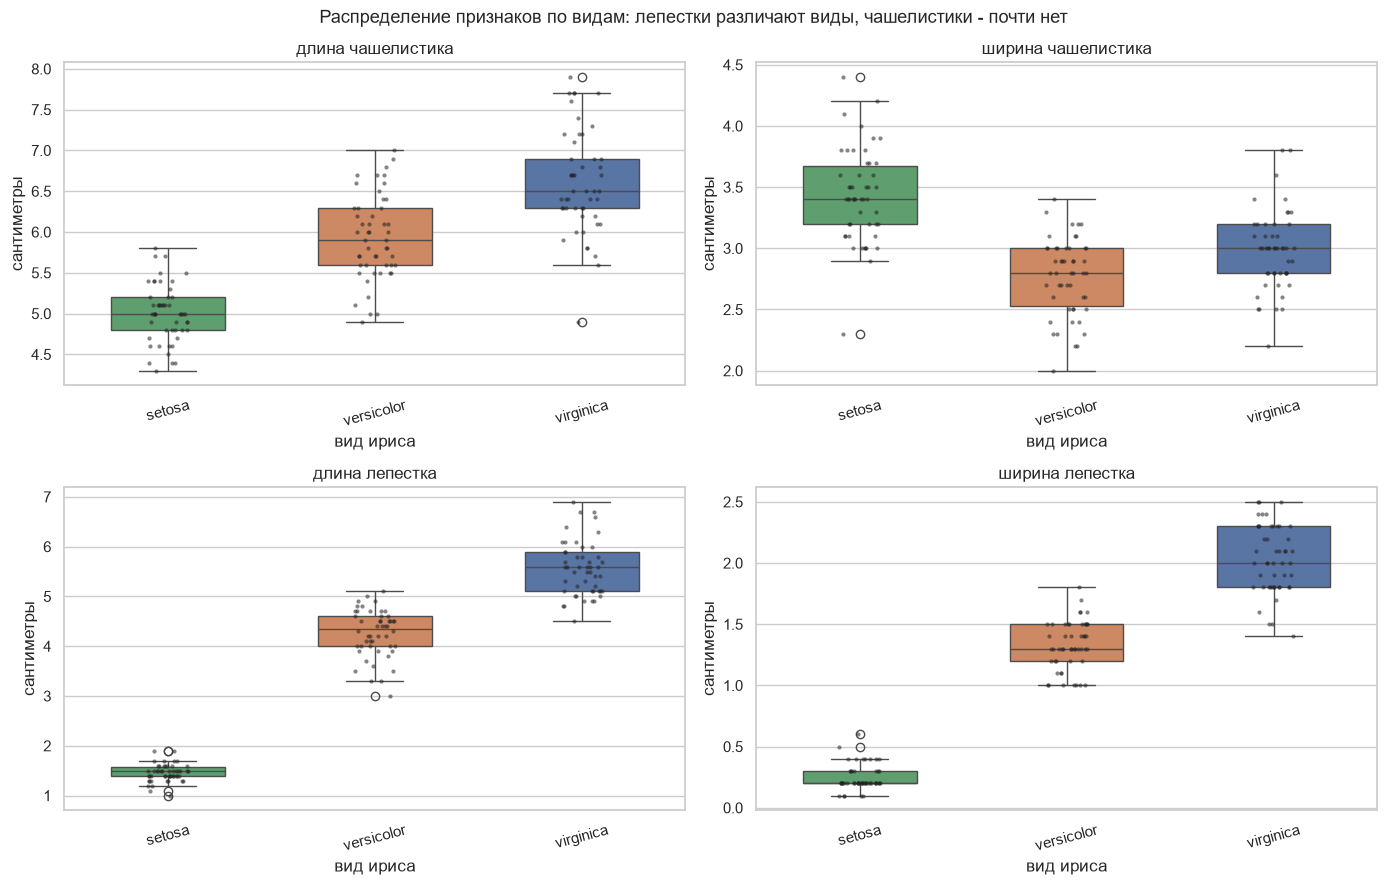

In [17]:
# Ящики с усами по классам. Ширина ящика - половина межквартильного размаха,
# усики - границы "не выбросов", точки - отдельные цветки.
figure, axes = plt.subplots(2, 2, figsize=(14, 9))

for axis, column in zip(axes.ravel(), FEATURE_COLUMNS):
    sns.boxplot(data=clean, x=TARGET, y=column, hue=TARGET, order=CLASS_NAMES,
                hue_order=CLASS_NAMES, palette=CLASS_COLORS, legend=False,
                width=0.55, ax=axis)
    sns.stripplot(data=clean, x=TARGET, y=column, order=CLASS_NAMES,
                  color="#222222", size=3, alpha=0.55, ax=axis)
    axis.set_title(FEATURE_RU[column])
    axis.set_xlabel("вид ириса")
    axis.set_ylabel("сантиметры")
    axis.tick_params(axis="x", rotation=15)

figure.suptitle("Распределение признаков по видам: лепестки различают виды, чашелистики - почти нет")
figure.tight_layout()
plt.show()


### 3.3 Ключевое наблюдение работы: `setosa` отделяется одним признаком

Посмотрим на ширину лепестка по видам в числах:

| вид | минимум | максимум | медиана |
|---|---|---|---|
| setosa | 0,1 | **0,6** | 0,2 |
| versicolor | **1,0** | 1,8 | 1,3 |
| virginica | 1,4 | 2,5 | 2,0 |

Между самым широким `setosa` (0,6 см) и самым узким из остальных (1,0 см)
остаётся **зазор 0,4 см**. То есть существует одно-единственное правило:

> **если ширина лепестка меньше 0,75 см - это `setosa`, иначе - не `setosa`.**

Проверим его прямо на данных: сколько цветков нарушают это правило.


In [18]:
# Проверяем ручное правило на всех строках. Считаем бинарную задачу
# "setosa или не setosa" - именно её и решает первый порог любого дерева.
petal_width = clean["petal width (cm)"]
petal_length = clean["petal length (cm)"]
THRESHOLD_WIDTH = 0.75      # середина зазора между 0,6 и 1,0 см
THRESHOLD_LENGTH = 2.45     # середина зазора между 1,9 и 3,0 см

is_setosa_rule = petal_width < THRESHOLD_WIDTH
is_setosa_true = clean[TARGET] == "setosa"

print(f"цветков с шириной лепестка < {THRESHOLD_WIDTH} см: {int(is_setosa_rule.sum())}")
print(f"из них не setosa: {int((is_setosa_rule & ~is_setosa_true).sum())}")
print(f"setosa с шириной >= {THRESHOLD_WIDTH} см: "
      f"{int((~is_setosa_rule & is_setosa_true).sum())}")
print(f"ошибок бинарного правила: {int((is_setosa_rule != is_setosa_true).sum())} "
      f"из {len(clean)}")

# То же самое по длине лепестка: зазор тоже есть, и он даже больше.
is_setosa_by_length = petal_length < THRESHOLD_LENGTH
print(f"по длине лепестка < {THRESHOLD_LENGTH} см ошибок: "
      f"{int((is_setosa_by_length != is_setosa_true).sum())}")

# Числа разбивки - то, что потом напечатает первое правило дерева.
separation_table = pd.DataFrame({
    "видимые цветки": clean[petal_width < THRESHOLD_WIDTH][TARGET].value_counts(),
    "остальные": clean[petal_width >= THRESHOLD_WIDTH][TARGET].value_counts(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
separation_table.index.name = "вид"
display(separation_table)
print("столбец «видимые цветки» - это в точности класс setosa (50 шт.),")
print("столбец «остальные» - два других вида вперемешку")


цветков с шириной лепестка < 0.75 см: 50
из них не setosa: 0
setosa с шириной >= 0.75 см: 0
ошибок бинарного правила: 0 из 149
по длине лепестка < 2.45 см ошибок: 0


,видимые цветки,остальные
вид,,
setosa,50,0
versicolor,0,50
virginica,0,49


столбец «видимые цветки» - это в точности класс setosa (50 шт.),
столбец «остальные» - два других вида вперемешку


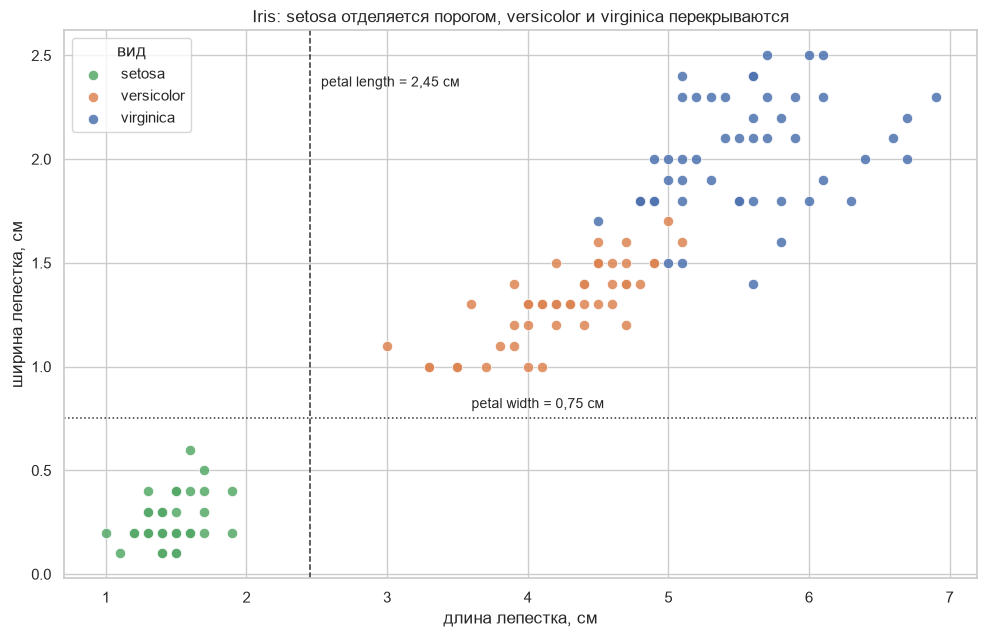

In [19]:
# Главный график работы: два признака лепестка на плоскости. Видно, что
# setosa стоит в отдельной левой нижней группе, а versicolor и virginica
# перекрываются - именно из-за этого перекрытия дерево ошибается.
figure, axis = plt.subplots(figsize=(10, 6.5))

for name in CLASS_NAMES:
    part = clean[clean[TARGET] == name]
    axis.scatter(part["petal length (cm)"], part["petal width (cm)"],
                 s=55, alpha=0.85, label=name, color=CLASS_COLORS[name],
                 edgecolor="white", linewidth=0.6)

# Оба порога: вертикаль отделяет setosa, горизонталь делит оставшихся надвое.
axis.axvline(THRESHOLD_LENGTH, color="#333333", linestyle="--", linewidth=1.1)
axis.axhline(THRESHOLD_WIDTH, color="#333333", linestyle=":", linewidth=1.1)
axis.text(THRESHOLD_LENGTH + 0.08, 2.35, "petal length = 2,45 см", fontsize=10)
axis.text(3.6, THRESHOLD_WIDTH + 0.05, "petal width = 0,75 см", fontsize=10)

axis.set_xlabel("длина лепестка, см")
axis.set_ylabel("ширина лепестка, см")
axis.set_title("Iris: setosa отделяется порогом, versicolor и virginica перекрываются")
axis.legend(title="вид")
figure.tight_layout()
plt.show()


### 3.4 Где именно классы перекрываются

`setosa` отделился идеально, а вот `versicolor` и `virginica` перекрываются по
ширине лепестка: у части `versicolor` лепесток шире 1,7 см, а у части
`virginica` - уже 1,7 см. Посчитаем, сколько именно цветков попадают в
зазор: это не ошибки данных, а **принципиальный предел** точности для этого
признака.


In [20]:
# Сколько цветков двух видов попадает в зону перекрытия.
rest = clean[clean[TARGET] != "setosa"]
BORDER = 1.70        # порог, который подобрало дерево на обучающей выборке

too_wide_versicolor = rest[(rest[TARGET] == "versicolor") & (rest["petal width (cm)"] > BORDER)]
too_narrow_virginica = rest[(rest[TARGET] == "virginica") & (rest["petal width (cm)"] <= BORDER)]

print(f"versicolor с шириной лепестка > {BORDER} см: {len(too_wide_versicolor)}")
print(f"virginica с шириной лепестка <= {BORDER} см: {len(too_narrow_virginica)}")
print(f"всего цветков в зоне перекрытия: {len(too_wide_versicolor) + len(too_narrow_virginica)} "
      f"из {len(rest)}")
print()
print("именно они:")
display(pd.concat([too_wide_versicolor, too_narrow_virginica])
        [FEATURE_COLUMNS + [TARGET]].sort_values("petal width (cm)"))

# Максимум, которого можно достичь на этом признаке при любом пороге.
best_possible = 1 - (len(too_wide_versicolor) + len(too_narrow_virginica)) / len(clean)
print(f"\nзначит, порог по ширине лепестка не может дать точность выше {best_possible:.4f}")
print("это не недостаток модели, а свойство данных")


versicolor с шириной лепестка > 1.7 см: 1
virginica с шириной лепестка <= 1.7 см: 5
всего цветков в зоне перекрытия: 6 из 99

именно они:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
134,6.1,2.6,5.6,1.4,virginica
119,6.0,2.2,5.0,1.5,virginica
133,6.3,2.8,5.1,1.5,virginica
129,7.2,3.0,5.8,1.6,virginica
106,4.9,2.5,4.5,1.7,virginica
70,5.9,3.2,4.8,1.8,versicolor



значит, порог по ширине лепестка не может дать точность выше 0.9597
это не недостаток модели, а свойство данных


### 3.5 Матрица корреляций

Здесь признаки числовые, поэтому корреляция Пирсона уместна (для категориальных
признаков она была бы бессмысленной). Чтобы включить в матрицу цель, кодируем
вид числами 0, 1, 2 - **только ради подсчёта корреляции**, в модель такая
переменная не пойдёт, потому что её порядок выдуман.

Из матрицы видно две вещи:

* **лепестки почти дублируют друг друга** (0,96), но оба сильно связаны с
  видом (0,95 и 0,96) - это и есть работающие признаки;
* **ширина чашелистика связана с видом отрицательно** (-0,42) и в дерево
  вообще не попадает.


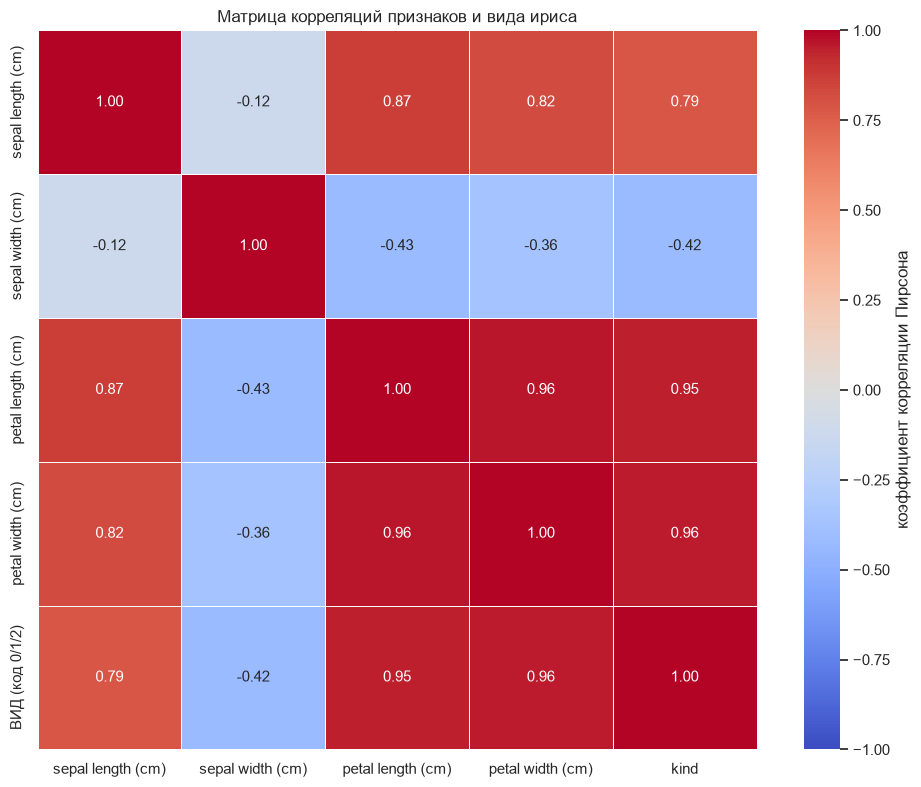

,связь с видом
sepal length (cm),0.787
sepal width (cm),-0.423
petal length (cm),0.949
petal width (cm),0.957


самые связанные пары признаков:
petal length (cm)  petal width (cm)     0.963
sepal length (cm)  petal length (cm)    0.874
                   petal width (cm)     0.821
sepal width (cm)   petal length (cm)    0.426
                   petal width (cm)     0.363
sepal length (cm)  sepal width (cm)     0.118
dtype: float64


In [21]:
# Матрица корреляций
CLASS_CODES = {"setosa": 0, "versicolor": 1, "virginica": 2}
correlation_frame = clean.assign(kind=clean[TARGET].map(CLASS_CODES))
correlation = correlation_frame[FEATURE_COLUMNS + ["kind"]].corr()
correlation = correlation.rename(index={"kind": "ВИД (код 0/1/2)"})

figure, axis = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.6,
            cbar_kws={"label": "коэффициент корреляции Пирсона"}, ax=axis)
axis.set_title("Матрица корреляций признаков и вида ириса")
figure.tight_layout()
plt.show()

display(correlation.loc["ВИД (код 0/1/2)", FEATURE_COLUMNS].round(3).to_frame("связь с видом"))

# Самая сильная пара признаков - мультиколлинеарность: они говорят почти об
# одном и том же, поэтому дерево использует один, а второй оставляет без нужды.
feature_correlation = correlation.loc[FEATURE_COLUMNS, FEATURE_COLUMNS]
upper_triangle = np.triu(np.ones(feature_correlation.shape, dtype=bool), k=1)
pairs = feature_correlation.abs().where(upper_triangle).stack().dropna()
print("самые связанные пары признаков:")
print(pairs.sort_values(ascending=False).round(3))


### 3.6 Вторая мера информативности - взаимная информация

Корреляция Пирсона умеет только одно: ловить **линейную** связь. Но дерево
строит правила вида «признак больше порога», то есть ищет **нелинейную**
связь. Поэтому нужна вторая мера - **взаимная информация** (mutual
information, MI): сколько бит знания о виде даёт знание признака.

Здесь она особенно уместна по трём причинам:

* у неё нет единицы «минус», и она честно показывает, насколько признак
  **близок к полному разделению**;
* она не предполагает, что зависимость линейная, - а в этом датасете вид
  разделяется именно порогом;
* её максимум известен заранее: для трёх равных классов это $\log_2 3 = 1{,}585$
  бита, и MI около 0,99 бита - это уже 63% от возможного.

Оценка MI на непрерывных признаках делается методом k ближайших соседей, и
она **слегка смещена вверх**, особенно на маленьких выборках. Поэтому
сравнивать надо значения **между собой**, а не с теорией.


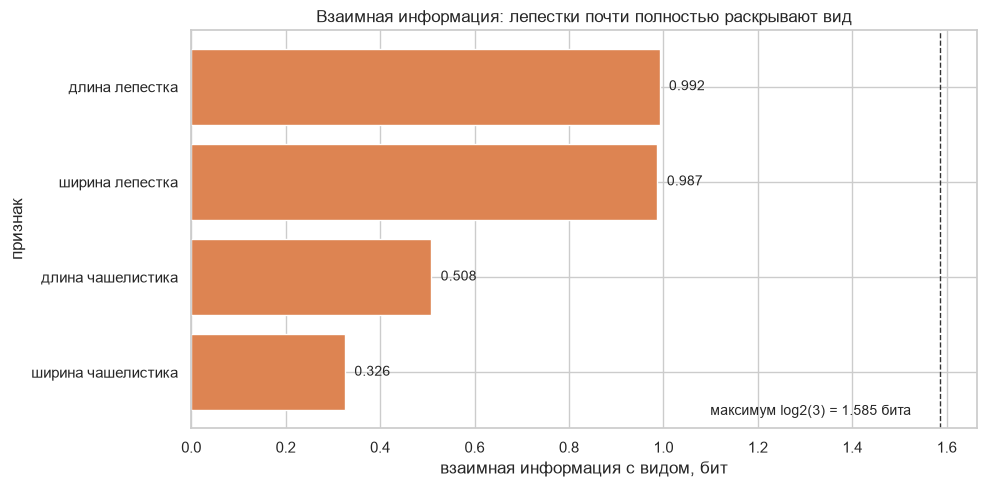

,"взаимная информация, бит"
длина лепестка,0.9918
ширина лепестка,0.9874
длина чашелистика,0.5084
ширина чашелистика,0.3256


максимально возможная MI для трёх равных классов: log2(3) = 1.5850 бита
доля лепестка длиной от максимума: 62.6%
доля ширины чашелистика от максимума: 20.5%


In [22]:
# Взаимная информация каждого признака с видом. discrete_features=False,
# потому что признаки непрерывные: оценщик сам разобьёт их на интервалы.
mutual_info = mutual_info_classif(
    clean[FEATURE_COLUMNS].to_numpy(),
    clean[TARGET].to_numpy(),
    discrete_features=False,
    random_state=SEED,
)

mi_table = pd.Series(mutual_info, index=[FEATURE_RU[column] for column in FEATURE_COLUMNS])
mi_table = mi_table.sort_values(ascending=False).rename("взаимная информация, бит")

maximum_bits = float(np.log2(len(CLASS_NAMES)))
figure, axis = plt.subplots(figsize=(10, 5))
bars = axis.barh(mi_table.index[::-1], mi_table.values[::-1], color="#DD8452")
axis.axvline(maximum_bits, color="#333333", linestyle="--", linewidth=1)
axis.text(maximum_bits - 0.06, -0.45, f"максимум log2(3) = {maximum_bits:.3f} бита",
          fontsize=10, ha="right")
axis.set_xlabel("взаимная информация с видом, бит")
axis.set_ylabel("признак")
axis.set_title("Взаимная информация: лепестки почти полностью раскрывают вид")
for bar, value in zip(bars, mi_table.values[::-1]):
    axis.text(value + 0.02, bar.get_y() + bar.get_height() / 2, f"{value:.3f}",
              va="center", fontsize=10)
figure.tight_layout()
plt.show()

display(mi_table.round(4).to_frame())
print(f"максимально возможная MI для трёх равных классов: log2(3) = {maximum_bits:.4f} бита")
print(f"доля лепестка длиной от максимума: {mi_table.iloc[0] / maximum_bits:.1%}")
print(f"доля ширины чашелистика от максимума: {mi_table.iloc[-1] / maximum_bits:.1%}")


## 4. Подготовка данных

Кодировать нечего: все четыре признака числовые, категориальных нет.
Масштабировать нечего: дерево сравнивает значения с порогами и от единиц
измерения не зависит, - прибавление сантиметра к обоим концам условия не
меняет ни одного разбиения. Проверка типов в разделе 1 это уже показала,
поэтому здесь только разделение выборки.

Делим **60 / 20 / 20 со стратификацией**. Стратификация нужна, чтобы в каждой
части сохранились пропорции классов: на таком маленьком наборе иначе во
валидации или тесте могло бы оказаться 9 цветков вместо 10.

**Честное замечание о размере.** После очистки остаётся 149 строк, поэтому
тест - это 30 цветков, а одна ошибка стоит 3,3 процентного пункта.
Различить модели, отличающиеся на две ошибки, такая выборка физически не
может. Поэтому выбор гиперпараметров мы подтверждаем ещё и кросс-валидацией
на обучающей части, а окончательные выводы о точности делаем с оговоркой на
её размер.


In [23]:
# Разделение 60 / 20 / 20
X = clean[FEATURE_COLUMNS]
y = clean[TARGET]

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=SEED, stratify=y_rest)

split_table = pd.DataFrame({
    "выборка": ["обучающая", "валидационная", "тестовая"],
    "строк": [len(X_train), len(X_val), len(X_test)],
})
for name, part in (("setosa", "setosa"), ("versicolor", "versicolor"),
                   ("virginica", "virginica")):
    split_table[name] = [
        int((y_train == part).sum()), int((y_val == part).sum()), int((y_test == part).sum())
    ]
split_table = split_table.set_index("выборка")
display(split_table)

print(f"признаков в матрице X: {X.shape[1]}, типы данных: {set(X.dtypes.astype(str))}")
print(f"одна ошибка на тесте стоит {100 / len(y_test):.2f} п.п. - выборка очень маленькая")
print(f"доли классов в train: {(y_train.value_counts(normalize=True).round(3)).to_dict()}")
print(f"доли классов в test: {(y_test.value_counts(normalize=True).round(3)).to_dict()}")


,строк,setosa,versicolor,virginica
выборка,,,,
обучающая,89,30,30,29
валидационная,30,10,10,10
тестовая,30,10,10,10


признаков в матрице X: 4, типы данных: {'float64'}
одна ошибка на тесте стоит 3.33 п.п. - выборка очень маленькая
доли классов в train: {'setosa': 0.337, 'versicolor': 0.337, 'virginica': 0.326}
доли классов в test: {'versicolor': 0.333, 'setosa': 0.333, 'virginica': 0.333}


## 5. Модель

Используем `DecisionTreeClassifier`. Он строит дерево из вопросов вида
«признак $\le$ порога?» и в каждом листе записывает класс, которого там
больше всего. Важные гиперпараметры:

* **`criterion`** - «джини» (неравномерность долей в листе) или энтропия; на
  этом наборе деревья совпадают до последнего листа, поэтому берём стандартное
  «джини», оно считается быстрее;
* **`max_depth`** - максимальная глубина. Главный рычаг против переобучения:
  глубокое дерево выучивает обучающую выборку, но хуже работает на новых
  цветках;
* **`min_samples_leaf`** - минимальное число цветков в листе. Запрещает строить
  правило «вот этот единственный цветок - `virginica`»;
* **`random_state`** - для воспроизводимости.

Дерево здесь уместно ещё и потому, что у него нет шага обучения в привычном
смысле: он не итерирует градиентный спуск, а строит разбиения жадно. Поэтому
`fit` отрабатывает мгновенно, а «модель» целиком помещается в трёх строках
текста - её можно прочитать и показать.


In [24]:
def build_tree(**hyperparameters):
    """Собирает дерево решений с заданными ограничениями сложности."""
    return DecisionTreeClassifier(
        criterion="gini",        # мера неравномерности в листе: стандартная и быстрая
        splitter="best",         # перебираем все варианты порога, а не делим наугад
        random_state=SEED,       # без него дерево каждый раз было бы немного другим
        **hyperparameters,
    )


print(build_tree(max_depth=2))
print()
print("поддерживаемые пороги: max_depth=None - без ограничения, "
      "min_samples_leaf=1 - листья из одного цветка")


DecisionTreeClassifier(max_depth=2, random_state=42)

поддерживаемые пороги: max_depth=None - без ограничения, min_samples_leaf=1 - листья из одного цветка


## 6. Обучение

### 6.1 Неглубокое дерево, которое можно прочитать

Начинаем с дерева глубины 2 - трёх листьев и двух вопросов. Глубокое дерево
на этом датасете нарисовалось бы красиво, но прочитать его нельзя, а
неглубокое даёт правила, которые можно буквально пересказать словами: именно
их и спросят на защите.


In [25]:
# Усреднение метрик по макро (average="macro"): каждый класс
# считается отдельно, поэтому ни один не забывается из-за размера выборки.
AVERAGE = "macro"

print("усреднение метрик по классам:", AVERAGE)
print("ROC-AUC считаем как one-vs-rest: отдельно AUC для каждого класса,")
print("в sklearn для этого обязателен параметр multi_class='ovr'")


усреднение метрик по классам: macro
ROC-AUC считаем как one-vs-rest: отдельно AUC для каждого класса,
в sklearn для этого обязателен параметр multi_class='ovr'


In [26]:
shallow_tree = build_tree(max_depth=2).fit(X_train, y_train)

print(f"глубина дерева:        {shallow_tree.get_depth()}")
print(f"листьев:               {shallow_tree.get_n_leaves()}")
print(f"узлов в дереве:        {shallow_tree.tree_.node_count}")
print(f"ошибок на обучении:    {int((shallow_tree.predict(X_train) != np.asarray(y_train)).sum())} из {len(y_train)}")
print(f"accuracy на обучении:  {shallow_tree.score(X_train, y_train):.4f}")
print(f"accuracy на валидации: {shallow_tree.score(X_val, y_val):.4f}")


глубина дерева:        2
листьев:               3
узлов в дереве:        5
ошибок на обучении:    2 из 89
accuracy на обучении:  0.9775
accuracy на валидации: 0.9667


In [27]:
# Текстовый вид дерева: та же структура, но читается без картинки. Это
# главный аргумент в пользу дерева: те же правила помещаются в текст.
print(export_text(shallow_tree, feature_names=FEATURE_COLUMNS, decimals=2))


|--- petal length (cm) <= 2.45
|   |--- class: setosa
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.70
|   |   |--- class: versicolor
|   |--- petal width (cm) >  1.70
|   |   |--- class: virginica



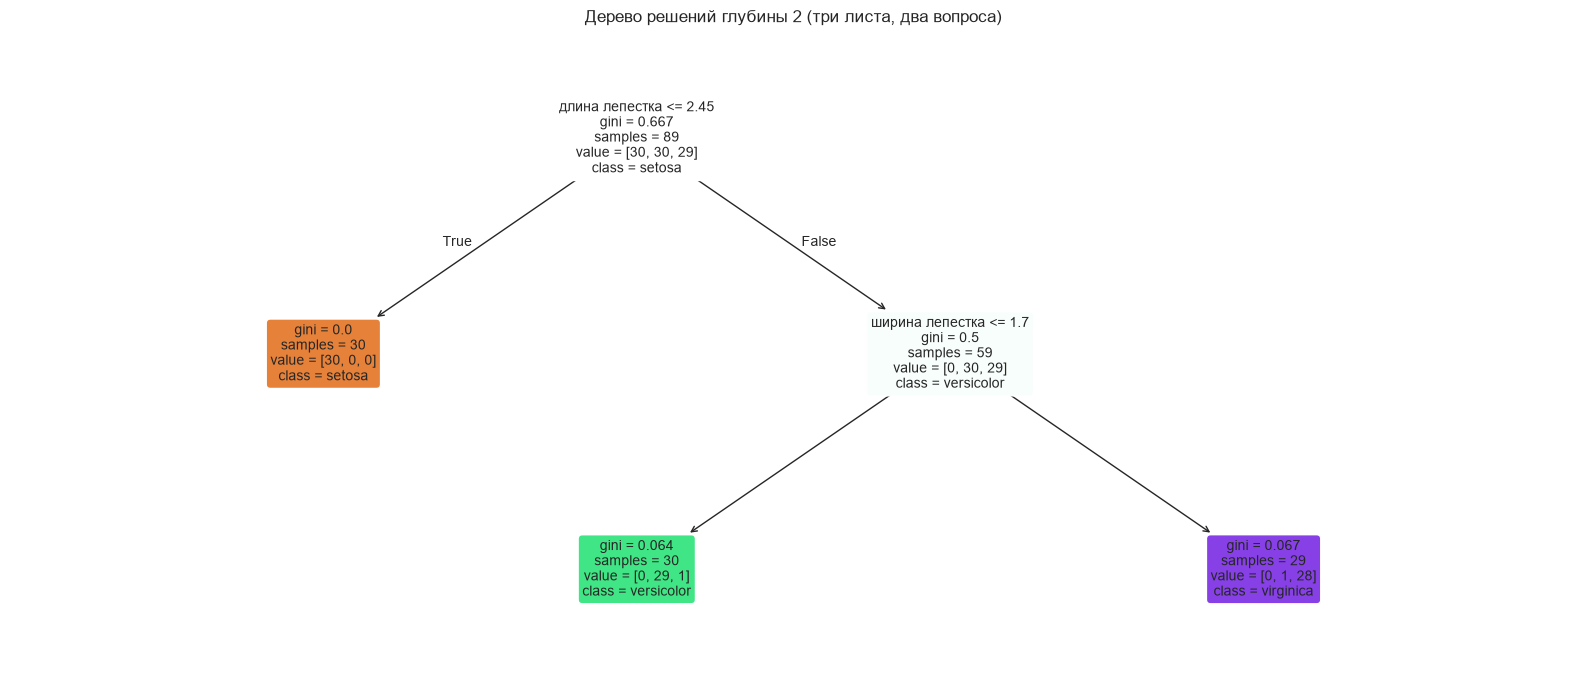

In [28]:
# Схема дерева на matplotlib - внешних программ (graphviz) не требуется.
figure, axis = plt.subplots(figsize=(16, 7))
plot_tree(shallow_tree,
          feature_names=[FEATURE_RU[column] for column in FEATURE_COLUMNS],
          class_names=list(shallow_tree.classes_),
          filled=True, rounded=True, fontsize=10, impurity=True, ax=axis)
axis.set_title("Дерево решений глубины 2 (три листа, два вопроса)")
figure.tight_layout()
plt.show()


#### Что означают правила этого дерева

Дерево задало **два вопроса** и получило **три листа**:

* **вопрос 1**: `petal length (cm) <= 2.45` - длина лепестка не больше 2,45 см
  (то есть меньше 2,5 см);
* **вопрос 2** (только для тех, кто прошёл первый): `petal width (cm) <= 1.70`
  - ширина лепестка не больше 1,7 см.

Правила целиком, словами:

1. длина лепестка меньше 2,45 см → **`setosa`**;
2. иначе, если ширина лепестка не больше 1,70 см → **`versicolor`**;
3. иначе → **`virginica`**.

Первый вопрос - это тот же приём, что и порог 0,75 см из раздела 3.3, только
взятый по длине лепестка: между максимумом у `setosa` (1,9 см) и минимумом у
остальных (3,0 см) тоже есть зазор, в который дерево и ставит порог. Почему
выбрана именно длина, а не ширина, покажем следующей ячейкой: там видно, что
оба порога подходят одинаково хорошо, и выбор между ними решает порядок
столбцов, а не качество признака.

**Главный вывод, который виден уже здесь.** Модель решает задачу фактически
**одним признаком**: 50 из 50 цветков `setosa` уходят в первый лист без единой
ошибки, а всё, что остаётся, сводится к одному порогу для двух других видов.
Красивые 97% на валидации измеряют здесь не сложность закономерности, а
удачный выбор порога по одному признаку.


In [29]:
# Проверяем, почему первым выбран порог по длине лепестка. Для каждого из
# двух «идеальных» порогов считаем выигрыш в джини: во сколько раз разбиение
# улучшило неравномерность в корне.
def root_gain(feature):
    """Выигрыш первого разбиения по одному признаку: джини в корне минус джини после."""
    probe = build_tree(max_depth=1).fit(X_train[[feature]], y_train)
    node = probe.tree_
    left, right = node.weighted_n_node_samples[1], node.weighted_n_node_samples[2]
    return (node.impurity[0]
            - (left * node.impurity[1] + right * node.impurity[2])
            / node.weighted_n_node_samples[0])


gain_length = root_gain("petal length (cm)")
gain_width = root_gain("petal width (cm)")
print(f"выигрыш от порога по длине лепестка:  {gain_length:.6f}")
print(f"выигрыш от порога по ширине лепестка: {gain_width:.6f}")
print(f"разница: {abs(gain_length - gain_width):.6f}")
print("оба порога отделяют setosa без единой ошибки, поэтому выигрыш")
print("совпадает до шестого знака, и выбор между ними решает порядок")
print("столбцов: длина лепестка стоит в таблице раньше ширины")

# Главная проверка раздела: сколько признаков нужно дереву на самом деле.
# Обучаем такие же деревья, но разрешаем смотреть только на один признак.
single_feature_report = []
for label, columns in (("только ширина лепестка", ["petal width (cm)"]),
                       ("только длина лепестка", ["petal length (cm)"]),
                       ("оба лепестка", ["petal width (cm)", "petal length (cm)"]),
                       ("все четыре признака", FEATURE_COLUMNS)):
    model = build_tree(max_depth=2).fit(X_train[columns], y_train)
    single_feature_report.append({
        "набор признаков": label,
        "accuracy_train": round(model.score(X_train[columns], y_train), 4),
        "accuracy_val": round(model.score(X_val[columns], y_val), 4),
        "листьев": model.get_n_leaves(),
    })

single_feature_table = pd.DataFrame(single_feature_report).set_index("набор признаков")
display(single_feature_table)
print("вывод: дерево, которому оставили только ширину лепестка, работает")
print("точно так же, как дерево на всех четырёх признаках - то есть три из")
print("четырёх признаков можно выбросить без потери точности")


выигрыш от порога по длине лепестка:  0.335217
выигрыш от порога по ширине лепестка: 0.335217
разница: 0.000000
оба порога отделяют setosa без единой ошибки, поэтому выигрыш
совпадает до шестого знака, и выбор между ними решает порядок
столбцов: длина лепестка стоит в таблице раньше ширины


,accuracy_train,accuracy_val,листьев
набор признаков,,,
только ширина лепестка,0.9775,0.9667,3
только длина лепестка,0.9663,0.8667,3
оба лепестка,0.9775,0.9667,3
все четыре признака,0.9775,0.9667,3


вывод: дерево, которому оставили только ширину лепестка, работает
точно так же, как дерево на всех четырёх признаках - то есть три из
четырёх признаков можно выбросить без потери точности


### 6.2 Подбор гиперпараметров по валидации

Перебираем глубину и минимальный размер листа и смотрим точность **на
валидации**. Тестовая выборка в этом переборе не участвует ни разу: подбирать
параметры по тесту - значит подбирать их под ответ, и оценка становится
нечестной.

Сетка небольшая: шесть значений глубины (плюс «без ограничения») и четыре
значения размера листа.


In [30]:
depth_candidates = [1, 2, 3, 4, 5, None]
leaf_candidates = [1, 2, 3, 5]

grid_results = []
for max_depth in depth_candidates:
    for min_leaf in leaf_candidates:
        candidate = build_tree(max_depth=max_depth, min_samples_leaf=min_leaf)
        candidate.fit(X_train, y_train)
        grid_results.append({
            "max_depth": max_depth if max_depth is not None else "без ограничения",
            "min_samples_leaf": min_leaf,
            "глубина": candidate.get_depth(),
            "листьев": candidate.get_n_leaves(),
            "train": round(candidate.score(X_train, y_train), 4),
            "val": round(candidate.score(X_val, y_val), 4),
        })

grid_table = pd.DataFrame(grid_results)
display(grid_table)

best_value = grid_table["val"].max()
winners = grid_table[grid_table["val"] == best_value]
print(f"лучшая точность на валидации: {best_value:.4f}")
print("достигают её конфигурации:")
for _, row in winners.iterrows():
    print(f"    max_depth={row['max_depth']}, min_samples_leaf={row['min_samples_leaf']}"
          f"  (листьев: {row['листьев']})")


,max_depth,min_samples_leaf,глубина,листьев,train,val
0,1,1,1,2,0.6742,0.6667
1,1,2,1,2,0.6742,0.6667
2,1,3,1,2,0.6742,0.6667
3,1,5,1,2,0.6742,0.6667
4,2,1,2,3,0.9775,0.9667
5,2,2,2,3,0.9775,0.9667
6,2,3,2,3,0.9775,0.9667
7,2,5,2,3,0.9775,0.9667
8,3,1,3,5,0.9775,0.9333
9,3,2,3,5,0.9775,0.9333


лучшая точность на валидации: 0.9667
достигают её конфигурации:
    max_depth=2, min_samples_leaf=1  (листьев: 3)
    max_depth=2, min_samples_leaf=2  (листьев: 3)
    max_depth=2, min_samples_leaf=3  (листьев: 3)
    max_depth=2, min_samples_leaf=5  (листьев: 3)
    max_depth=3, min_samples_leaf=3  (листьев: 5)
    max_depth=3, min_samples_leaf=5  (листьев: 5)
    max_depth=4, min_samples_leaf=3  (листьев: 5)
    max_depth=4, min_samples_leaf=5  (листьев: 5)
    max_depth=5, min_samples_leaf=3  (листьев: 5)
    max_depth=5, min_samples_leaf=5  (листьев: 5)
    max_depth=без ограничения, min_samples_leaf=3  (листьев: 5)
    max_depth=без ограничения, min_samples_leaf=5  (листьев: 5)


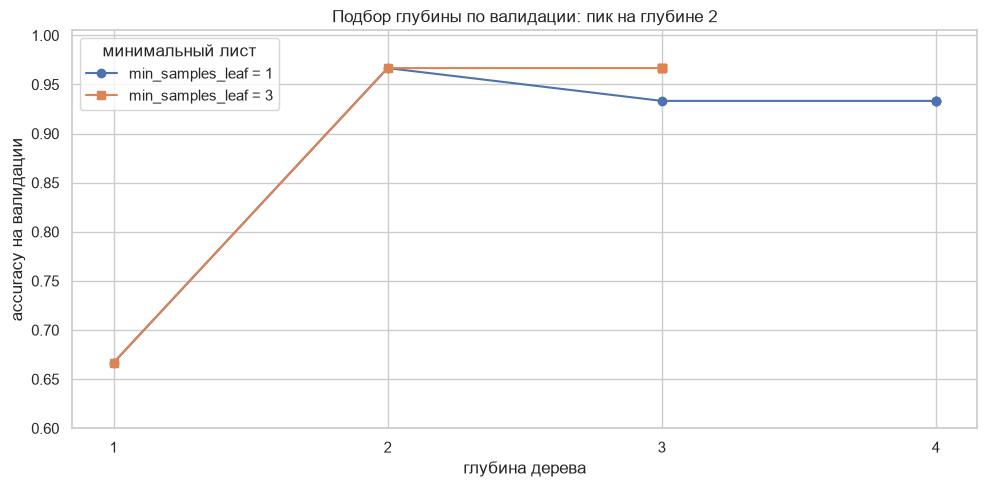

разброс по валидации: от 0.6667 до 0.9667, то есть 9 цветков из 30
вывод: точность выходит на плато уже с глубины 2, дальше дерево
только запоминает отдельные цветки обучающей выборки


In [31]:
# Кривые точности на валидации по глубине. Видно, что после глубины 2 линия
# не растёт, а уходит вниз: усложнение дерева здесь не помогает.
figure, axis = plt.subplots(figsize=(10, 5))

for min_leaf, marker in ((1, "o"), (3, "s")):
    curve = grid_table[grid_table["min_samples_leaf"] == min_leaf]
    axis.plot(curve["глубина"], curve["val"], marker=marker,
              label=f"min_samples_leaf = {min_leaf}")

axis.set_xticks(sorted(grid_table["глубина"].unique()))
axis.set_ylim(0.6, 1.005)
axis.set_xlabel("глубина дерева")
axis.set_ylabel("accuracy на валидации")
axis.set_title("Подбор глубины по валидации: пик на глубине 2")
axis.legend(title="минимальный лист")
figure.tight_layout()
plt.show()

# Разница между лучшим и худшим вариантом валидации в пересчёте на цветки:
# на 30 цветах валидации это буквально одна-две ошибки.
print(f"разброс по валидации: от {grid_table['val'].min():.4f} до {grid_table['val'].max():.4f}, "
      f"то есть {(grid_table['val'].max() - grid_table['val'].min()) * len(y_val):.0f} "
      f"цветков из {len(y_val)}")
print("вывод: точность выходит на плато уже с глубины 2, дальше дерево")
print("только запоминает отдельные цветки обучающей выборки")


### 6.3 Кросс-валидация: проверяем выбор на всей обучающей части

Выбор по валидации на 30 цветах ненадёжен: там разница между лучшим и
худним вариантом - это один-два цветка. Поэтому тот же перебор повторяем
**5-фолдовой стратифицированной кросс-валидацией** на всей обучающей части
(89 цветков, каждый цветок побывает и в обучении, и в проверке). Тестовая
выборка по-прежнему не участвует.

Кросс-валидация даёт не одну точку, а среднее и разброс по пяти folds - и
именно разброс показывает, насколько выбранная точность вообще надёжна.


,среднее,разброс,минимум,максимум
модель,,,,
глубина 1 (пень),0.6745,0.0157,0.6667,0.7059
глубина 2,0.9660,0.0278,0.9412,1.0000
глубина 3,0.9549,0.0418,0.8889,1.0000
без ограничения,0.9327,0.0414,0.8889,1.0000


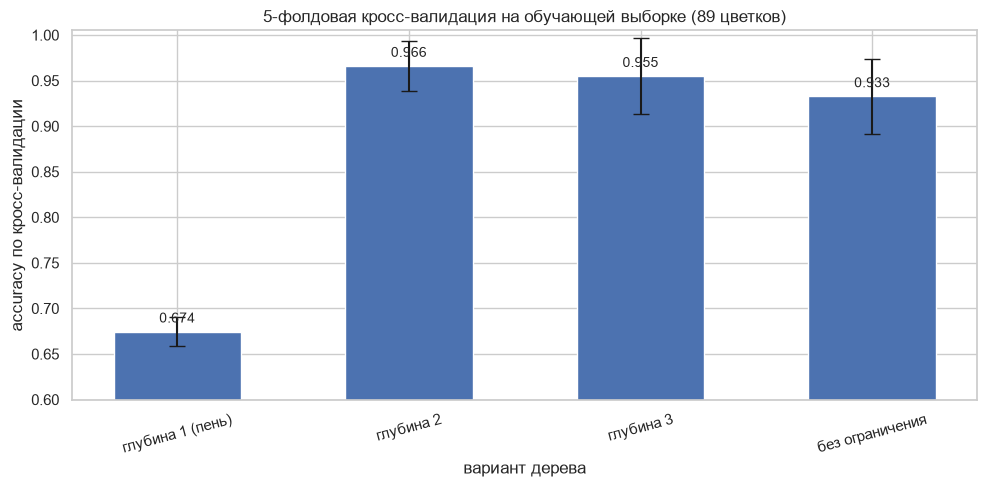

разброс у неограниченного дерева: 0.0414
то есть оно хуже не в среднем, а заметно менее устойчиво


In [32]:
# Кросс-валидация считается только на train: валидация и тест в ней не участвуют.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
for label, options in (("глубина 1 (пень)", dict(max_depth=1)),
                       ("глубина 2", dict(max_depth=2)),
                       ("глубина 3", dict(max_depth=3)),
                       ("без ограничения", dict())):
    folds = cross_val_score(build_tree(**options), X_train, y_train,
                            cv=cv, scoring="accuracy")
    cv_rows.append({
        "модель": label,
        "среднее": round(float(folds.mean()), 4),
        "разброс": round(float(folds.std()), 4),
        "минимум": round(float(folds.min()), 4),
        "максимум": round(float(folds.max()), 4),
    })

cv_table = pd.DataFrame(cv_rows).set_index("модель")
display(cv_table)

figure, axis = plt.subplots(figsize=(10, 5))
positions = np.arange(len(cv_table))
axis.bar(positions, cv_table["среднее"], 0.55, color="#4C72B0",
         yerr=cv_table["разброс"], capsize=6)
axis.set_xticks(positions)
axis.set_xticklabels(cv_table.index, rotation=15)
axis.set_ylim(0.6, 1.005)
axis.set_xlabel("вариант дерева")
axis.set_ylabel("accuracy по кросс-валидации")
axis.set_title("5-фолдовая кросс-валидация на обучающей выборке (89 цветков)")
for index, value in enumerate(cv_table["среднее"]):
    axis.text(index, value + 0.01, f"{value:.3f}", ha="center", fontsize=10)
figure.tight_layout()
plt.show()

print(f"разброс у неограниченного дерева: {cv_table.loc['без ограничения', 'разброс']:.4f}")
print("то есть оно хуже не в среднем, а заметно менее устойчиво")


### 6.4 Какая модель идёт в оценку

По валидации лучший результат дают сразу несколько конфигураций - это
классический признак слишком маленькой выборки. Дальше решаем по трём
правилам, и все три указывают в одну сторону:

1. **при равенстве берём самую простую модель**: у дерева глубины 2 всего
   три листа и два вопроса, у остальных - пять и больше;
2. **минимальный размер листа 1 не вредит**: все значения от 1 до 5 дали
   одинаковое дерево, а ограничение по листу на этом наборе нечего
   ограничивать;
3. **кросс-валидация подтверждает выбор**: глубина 2 даёт и лучшее среднее
   (0,966), и меньший разброс, чем неограниченное дерево (0,933).

Рабочей моделью берём **`max_depth = 2, min_samples_leaf = 1`**. Тестовая
выборка в выборе не участвовала ни разу.


### 6.5 Переобучение: ограниченное дерево против неограниченного

Переобучение - это когда модель выучила не закономерность, а обучающую
выборку: на ней ошибок ноль, а на новых цветках заметно больше. Сравним
дерево-пень, рабочее ограниченное дерево и дерево без ограничений.


In [33]:
unlimited_tree = build_tree().fit(X_train, y_train)
stump_tree = build_tree(max_depth=1).fit(X_train, y_train)


def leaf_summary(model):
    """Число листьев, их размеры и доля записей в «одиночных» листьях."""
    is_leaf = model.tree_.children_left == -1
    sizes = model.tree_.n_node_samples[is_leaf]
    return {
        "листьев": int(is_leaf.sum()),
        "минимальный лист": int(sizes.min()),
        "листьев-одиночек": int((sizes == 1).sum()),
        "записей в одиночках": int(sizes[sizes == 1].sum()),
    }


comparison = pd.DataFrame([
    {"модель": "пень (глубина 1)",
     "глубина": stump_tree.get_depth(),
     "accuracy_train": round(stump_tree.score(X_train, y_train), 4),
     "accuracy_val": round(stump_tree.score(X_val, y_val), 4),
     **leaf_summary(stump_tree)},
    {"модель": "рабочее (глубина 2)",
     "глубина": shallow_tree.get_depth(),
     "accuracy_train": round(shallow_tree.score(X_train, y_train), 4),
     "accuracy_val": round(shallow_tree.score(X_val, y_val), 4),
     **leaf_summary(shallow_tree)},
    {"модель": "без ограничения",
     "глубина": unlimited_tree.get_depth(),
     "accuracy_train": round(unlimited_tree.score(X_train, y_train), 4),
     "accuracy_val": round(unlimited_tree.score(X_val, y_val), 4),
     **leaf_summary(unlimited_tree)},
]).set_index("модель")
display(comparison)

print(f"ошибок на обучении у неограниченного дерева: "
      f"{int((unlimited_tree.predict(X_train) != np.asarray(y_train)).sum())} из {len(y_train)}")
print(f"разрыв train - val у неограниченного: "
      f"{unlimited_tree.score(X_train, y_train) - unlimited_tree.score(X_val, y_val):+.4f}")
print(f"разрыв train - val у ограниченного:   "
      f"{shallow_tree.score(X_train, y_train) - shallow_tree.score(X_val, y_val):+.4f}")


,глубина,accuracy_train,accuracy_val,листьев,минимальный лист,листьев-одиночек,записей в одиночках
модель,,,,,,,
пень (глубина 1),1,0.6742,0.6667,2,30,0,0
рабочее (глубина 2),2,0.9775,0.9667,3,29,0,0
без ограничения,4,1.0000,0.9333,7,1,4,4


ошибок на обучении у неограниченного дерева: 0 из 89
разрыв train - val у неограниченного: +0.0667
разрыв train - val у ограниченного:   +0.0109


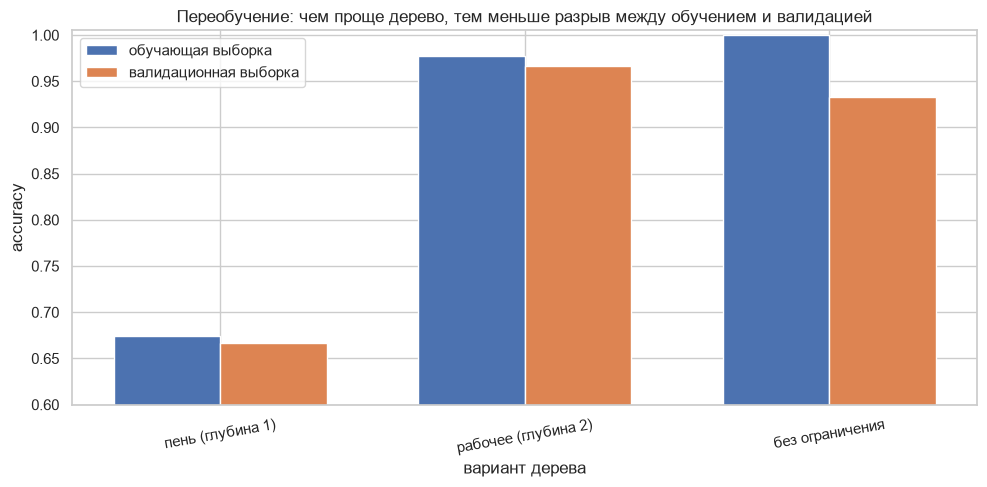

у неограниченного дерева 4 листа содержат по одному цветку - это и есть
прямой след запоминания обучающей выборки


In [34]:
# Тот же разрыв графиком: у неограниченного дерева провал между обучением
# и валидацией заметно больше.
figure, axis = plt.subplots(figsize=(10, 5))
bar_width = 0.35
positions = np.arange(len(comparison))

axis.bar(positions - bar_width / 2, comparison["accuracy_train"], bar_width,
         label="обучающая выборка", color="#4C72B0")
axis.bar(positions + bar_width / 2, comparison["accuracy_val"], bar_width,
         label="валидационная выборка", color="#DD8452")

axis.set_xticks(positions)
axis.set_xticklabels(comparison.index, rotation=10)
axis.set_ylim(0.6, 1.005)
axis.set_xlabel("вариант дерева")
axis.set_ylabel("accuracy")
axis.set_title("Переобучение: чем проще дерево, тем меньше разрыв между обучением и валидацией")
axis.legend()
figure.tight_layout()
plt.show()

print("у неограниченного дерева 4 листа содержат по одному цветку - это и есть")
print("прямой след запоминания обучающей выборки")


In [35]:
# Правила неограниченного дерева. Первые две строки - те же, что у рабочего
# дерева, а дальше идут ветви, которые описывают единичные цветки.
print(export_text(unlimited_tree, feature_names=FEATURE_COLUMNS, decimals=2))


|--- petal length (cm) <= 2.45
|   |--- class: setosa
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.70
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: versicolor
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |--- class: virginica
|   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |--- class: versicolor
|   |--- petal width (cm) >  1.70
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal length (cm) <= 6.05
|   |   |   |   |--- class: versicolor
|   |   |   |--- sepal length (cm) >  6.05
|   |   |   |   |--- class: virginica
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: virginica



**Что здесь видно, а что нет.** Числа честные и одновременно скромные:
неограниченное дерево выучило обучающую выборку идеально (ошибок 0 из 89), но
на валидации набрало 0,933 против 0,967 у ограниченного - то есть на трёх
цветах из тридцати. Разрыв «обучение минус валидация» вырос с 0,011 до 0,067.

Главный признак переобучения здесь не в метриках, а в структуре: у
неограниченного дерева появились **четыре листа, каждый из одного цветка**.
Правила вида `petal width <= 1,70 -> petal length <= 4,95 -> petal width <= 1,55`
описывают не закономерность вида, а конкретные записи из обучения. Ограничение
`max_depth=2` запрещает такие ветви по построению.


## 7. Оценка на тестовой выборке

Тестовая выборка открывается здесь - в первый и в последний раз. Ни один
гиперпараметр по ней не подбирался, а выбранная модель была зафиксирована в
разделе 6.4.

Считаем пять метрик:

* **accuracy** - доля правильно определённых видов;
* **precision, recall, F1** - в макро-усреднении по трём классам: каждый вид
  вносит в оценку одинаковый вклад;
* **ROC-AUC** - как one-vs-rest (отдельно для каждого вида) и в макро-усреднении.

Почему именно макро-усреднение, а не взвешенное: при равных классах разницы
нет, но при перекосе классов взвешенное усреднение начало бы замалчивать
редкий класс, а здесь ошибка на редком виде - самая дорогая.


In [36]:
# Базовая линия: модель, которая игнорирует все признаки и всегда
# предсказывает самый частый класс. Ниже неё результат бессмыслен.
baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline.fit(X_train, y_train)

print("класс, который всегда предсказывает базовая линия:",
      baseline.predict(X_test)[0])
print(f"accuracy базовой линии на тесте: "
      f"{accuracy_score(y_test, baseline.predict(X_test)):.4f}")
print(f"это ровно доля самого частого класса: "
      f"{baseline.predict_proba(X_test)[0].max():.4f}")


класс, который всегда предсказывает базовая линия: setosa
accuracy базовой линии на тесте: 0.3333
это ровно доля самого частого класса: 1.0000


In [37]:
def classification_metrics(true_labels, predictions, probabilities=None):
    """Accuracy, макро-Precision/Recall/F1 и ROC-AUC (one-vs-rest) для трёх классов."""
    result = {
        "accuracy": accuracy_score(true_labels, predictions),
        "precision": precision_score(true_labels, predictions,
                                     average=AVERAGE, zero_division=0),
        "recall": recall_score(true_labels, predictions, average=AVERAGE),
        "f1": f1_score(true_labels, predictions, average=AVERAGE, zero_division=0),
    }
    if probabilities is not None:
        result["roc_auc"] = roc_auc_score(true_labels, probabilities,
                                          multi_class="ovr", average=AVERAGE)
    return result


candidates = {
    "Dummy (базовая линия)": baseline,
    "Дерево-пень (глубина 1)": build_tree(max_depth=1).fit(X_train, y_train),
    "Дерево 5 / 3": build_tree(max_depth=5, min_samples_leaf=3).fit(X_train, y_train),
    "Дерево без ограничения": unlimited_tree,
    "Дерево 2 / 1 (рабочее)": shallow_tree,
}

test_results = pd.DataFrame([
    {"модель": name,
     **classification_metrics(y_test, model.predict(X_test),
                              model.predict_proba(X_test))}
    for name, model in candidates.items()
]).set_index("модель").round(4)
display(test_results)

work_accuracy = test_results.loc["Дерево 2 / 1 (рабочее)", "accuracy"]
base_accuracy = test_results.loc["Dummy (базовая линия)", "accuracy"]
print(f"прирост рабочей модели над базовой линией: {(work_accuracy - base_accuracy) * 100:.1f} п.п.")
print(f"в разах: {work_accuracy / base_accuracy:.2f}")

# Насколько вообще надёжна эта оценка: стандартная ошибка доли при n = 30.
standard_error = float(np.sqrt(work_accuracy * (1 - work_accuracy) / len(y_test)))
print(f"\nстандартная ошибка accuracy при n = {len(y_test)}: {standard_error:.4f}")
print(f"то есть доверительный интервал примерно "
      f"{work_accuracy - 2 * standard_error:.3f} .. {work_accuracy + 2 * standard_error:.3f}")
print("и этот интервал шире, чем разница между кандидатами")


,accuracy,precision,recall,f1,roc_auc
модель,,,,,
Dummy (базовая линия),0.3333,0.1111,0.3333,0.1667,0.5000
Дерево-пень (глубина 1),0.6667,0.5000,0.6667,0.5556,0.8333
Дерево 5 / 3,0.9000,0.9231,0.9000,0.8977,0.9150
Дерево без ограничения,0.9333,0.9444,0.9333,0.9327,0.9500
Дерево 2 / 1 (рабочее),0.9000,0.9231,0.9000,0.8977,0.9500


прирост рабочей модели над базовой линией: 56.7 п.п.
в разах: 2.70

стандартная ошибка accuracy при n = 30: 0.0548
то есть доверительный интервал примерно 0.790 .. 1.010
и этот интервал шире, чем разница между кандидатами


In [38]:
# Подробный отчёт по каждому виду для рабочей модели: видно, где именно
# теряются качество - а не в общей цифре.
work_predictions = shallow_tree.predict(X_test)
print(classification_report(y_test, work_predictions,
                            target_names=list(shallow_tree.classes_),
                            digits=4, zero_division=0))


              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.7692    1.0000    0.8696        10
   virginica     1.0000    0.7000    0.8235        10

    accuracy                         0.9000        30
   macro avg     0.9231    0.9000    0.8977        30
weighted avg     0.9231    0.9000    0.8977        30



предсказанный,setosa,versicolor,virginica
истинный,,,
setosa,10,0,0
versicolor,0,10,0
virginica,0,3,7


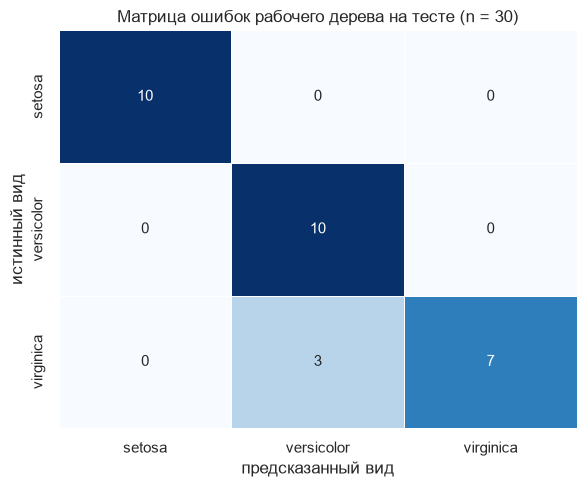

setosa     : верно 10 из 10, recall = 1.0000
versicolor : верно 10 из 10, recall = 1.0000
virginica  : верно 7 из 10, recall = 0.7000

всего ошибок: 3 из 30
все они одного типа: virginica принята за versicolor - это ровно зона
перекрытия, найденная в разделе 3.4


In [39]:
# Матрица ошибок: строки - истинный вид, столбцы - предсказанный.
error_matrix = confusion_matrix(y_test, work_predictions,
                                labels=list(shallow_tree.classes_))
error_table = pd.DataFrame(error_matrix, index=CLASS_NAMES, columns=CLASS_NAMES)
error_table.index.name = "истинный"
error_table.columns.name = "предсказанный"
display(error_table)

figure, axis = plt.subplots(figsize=(6, 5))
sns.heatmap(error_table, annot=True, fmt="d", cmap="Blues", ax=axis,
            cbar=False, linewidths=0.6)
axis.set_title(f"Матрица ошибок рабочего дерева на тесте (n = {len(y_test)})")
axis.set_xlabel("предсказанный вид")
axis.set_ylabel("истинный вид")
figure.tight_layout()
plt.show()

for name in CLASS_NAMES:
    total = int(error_table.loc[name].sum())
    correct = int(error_table.loc[name, name])
    print(f"{name:11s}: верно {correct} из {total}, recall = {correct / total:.4f}")

print(f"\nвсего ошибок: {int(error_table.to_numpy().sum() - np.trace(error_table))} "
      f"из {int(error_table.to_numpy().sum())}")
print("все они одного типа: virginica принята за versicolor - это ровно зона")
print("перекрытия, найденная в разделе 3.4")


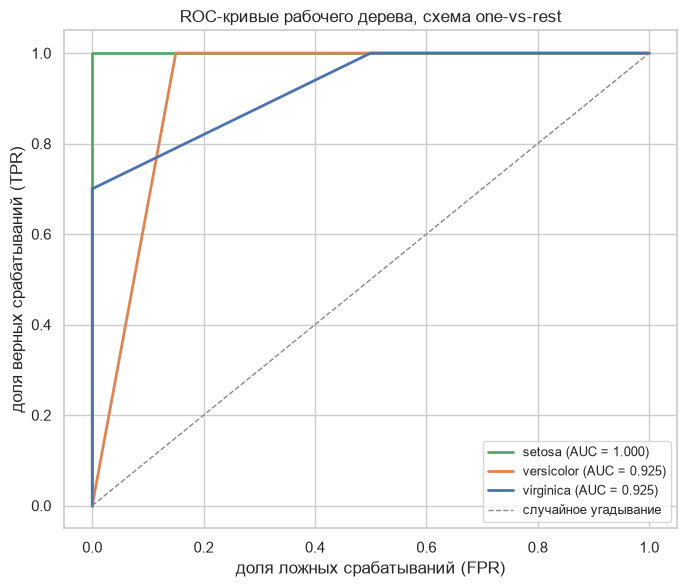

ROC-AUC (one-vs-rest, макро) рабочей модели: 0.9500
ROC-AUC базовой линии: 0.5000


In [40]:
# Для трёх классов ROC-кривую строят как три кривые one-vs-rest: каждая
# отвечает на вопрос "угадывает ли модель именно этот вид".
probabilities = shallow_tree.predict_proba(X_test)

figure, axis = plt.subplots(figsize=(7, 6))
for index, name in enumerate(shallow_tree.classes_):
    is_class = (np.asarray(y_test) == name).astype(int)
    false_positive, true_positive, _ = roc_curve(is_class, probabilities[:, index])
    area = roc_auc_score(is_class, probabilities[:, index])
    axis.plot(false_positive, true_positive, label=f"{name} (AUC = {area:.3f})",
              color=CLASS_COLORS[name], linewidth=2)

axis.plot([0, 1], [0, 1], linestyle="--", color="#888888", linewidth=1, label="случайное угадывание")
axis.set_xlabel("доля ложных срабатываний (FPR)")
axis.set_ylabel("доля верных срабатываний (TPR)")
axis.set_title("ROC-кривые рабочего дерева, схема one-vs-rest")
axis.legend(fontsize=9)
figure.tight_layout()
plt.show()

macro_auc = roc_auc_score(y_test, probabilities, multi_class="ovr", average=AVERAGE)
print(f"ROC-AUC (one-vs-rest, макро) рабочей модели: {macro_auc:.4f}")
print(f"ROC-AUC базовой линии: "
      f"{roc_auc_score(y_test, baseline.predict_proba(X_test), multi_class='ovr', average=AVERAGE):.4f}")


### 7.1 Важность признаков

`feature_importances_` показывает, какую долю суммарного уменьшения
неравномерности дал каждый признак. Это **не** «вклад признака в точность» и
не коэффициент влияния: это доля от суммы 1, посчитанная по обучению.

Смотреть надо с оговоркой. Если признак не попал ни в одно разбиение, его
важность ровно нулевая - но это не значит, что он бесполезен: на другом
разбиении он мог бы попасть в дерево. Поэтому рядом покажем ещё и важность
признаков неограниченного дерева.


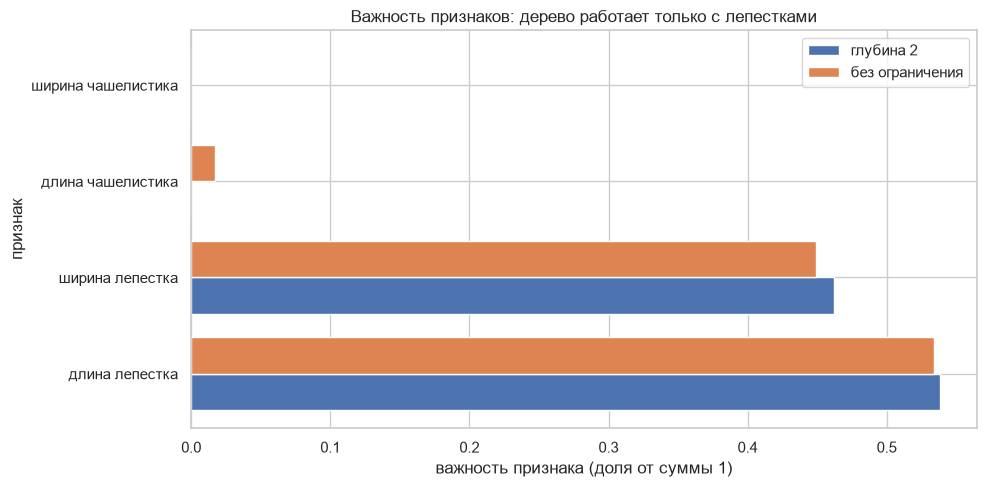

,рабочее дерево,без ограничения
длина лепестка,0.538,0.534
ширина лепестка,0.462,0.449
длина чашелистика,0.000,0.017
ширина чашелистика,0.000,0.000


два признака чашелистика в рабочем дереве дают 0% важности - то есть ноль
ширину чашелистика не использует ни одно из двух деревьев
это совпадает с выводами разведки: она почти не различает виды


In [41]:
feature_importance = pd.Series(
    shallow_tree.feature_importances_,
    index=[FEATURE_RU[column] for column in FEATURE_COLUMNS],
).sort_values(ascending=False)
unlimited_importance = pd.Series(
    unlimited_tree.feature_importances_,
    index=[FEATURE_RU[column] for column in FEATURE_COLUMNS],
)

importance_table = pd.DataFrame({
    "рабочее дерево": feature_importance.round(3),
    "без ограничения": unlimited_importance.round(3),
}).sort_values("рабочее дерево", ascending=False)

figure, axis = plt.subplots(figsize=(10, 5))
positions = np.arange(len(importance_table))
axis.barh(positions - 0.19, importance_table["рабочее дерево"], 0.38,
          label="глубина 2", color="#4C72B0")
axis.barh(positions + 0.19, importance_table["без ограничения"], 0.38,
          label="без ограничения", color="#DD8452")
axis.set_yticks(positions)
axis.set_yticklabels(importance_table.index)
axis.set_xlabel("важность признака (доля от суммы 1)")
axis.set_ylabel("признак")
axis.set_title("Важность признаков: дерево работает только с лепестками")
axis.legend()
figure.tight_layout()
plt.show()

display(importance_table)
sepal_share = float(importance_table["рабочее дерево"].tail(2).sum())
print(f"два признака чашелистика в рабочем дереве дают {sepal_share:.0%} важности - то есть ноль")
print("ширину чашелистика не использует ни одно из двух деревьев")
print("это совпадает с выводами разведки: она почти не различает виды")


### 7.2 Разбор конкретных ошибок

Общая цифра accuracy мало что говорит. Полезнее посмотреть, **на каких
цветках** модель ошибается и почему.


In [42]:
wrong_mask = np.asarray(work_predictions != y_test)
wrong_rows = clean.loc[X_test.index[wrong_mask]].copy()
wrong_rows.insert(0, "предсказано", work_predictions[wrong_mask])

print(f"ошибок на тесте: {int(wrong_mask.sum())} из {len(y_test)} ({wrong_mask.mean():.2%})")
display(wrong_rows)

error_pairs = (pd.DataFrame({
    "истинный вид": np.asarray(y_test)[wrong_mask],
    "предсказано": work_predictions[wrong_mask],
}).value_counts().rename("ошибок").reset_index())
display(error_pairs)

print(f"ширина лепестка у всех ошибочных цветков: "
      f"{list(wrong_rows['petal width (cm)'])} см - все не больше порога 1,70 см")


ошибок на тесте: 3 из 30 (10.00%)


,предсказано,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
129,versicolor,7.2,3.0,5.8,1.6,virginica
134,versicolor,6.1,2.6,5.6,1.4,virginica
133,versicolor,6.3,2.8,5.1,1.5,virginica


,истинный вид,предсказано,ошибок
0,virginica,versicolor,3


ширина лепестка у всех ошибочных цветков: [1.6, 1.4, 1.5] см - все не больше порога 1,70 см


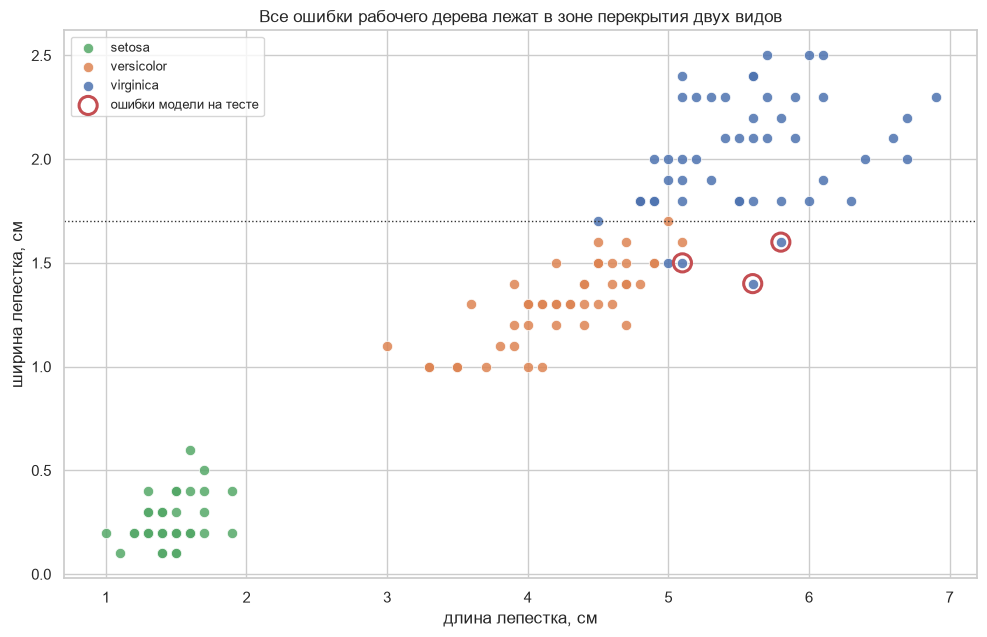

ошибок среди versicolor: 0, среди virginica: 3
то есть модель никогда не спутывает setosa с остальными - верно,
её первая развилка выбрана безошибочно


In [43]:
# ошибки на плоскости: все в зоне перекрытия двух видов
figure, axis = plt.subplots(figsize=(10, 6.5))

for name in CLASS_NAMES:
    part = clean[clean[TARGET] == name]
    axis.scatter(part["petal length (cm)"], part["petal width (cm)"],
                 s=55, alpha=0.85, label=name, color=CLASS_COLORS[name],
                 edgecolor="white", linewidth=0.6)

errors_only = wrong_rows
axis.scatter(errors_only["petal length (cm)"], errors_only["petal width (cm)"],
             s=170, facecolor="none", edgecolor="#C44E52", linewidth=2.2,
             label="ошибки модели на тесте")

axis.axhline(1.70, color="#333333", linestyle=":", linewidth=1)
axis.set_xlabel("длина лепестка, см")
axis.set_ylabel("ширина лепестка, см")
axis.set_title("Все ошибки рабочего дерева лежат в зоне перекрытия двух видов")
axis.legend(fontsize=9)
figure.tight_layout()
plt.show()

print(f"ошибок среди versicolor: "
      f"{int((wrong_rows['species'] == 'versicolor').sum())}, "
      f"среди virginica: {int((wrong_rows['species'] == 'virginica').sum())}")
print("то есть модель никогда не спутывает setosa с остальными - верно,")
print("её первая развилка выбрана безошибочно")


### 7.3 Честная проверка: много ли здесь сделала машина

Раздел 3.3 показал, что `setosa` отделяется **одним** порогом по ширине
лепестка без единой ошибки. Проверим, сколько стоит остальное обучение:
сравним дерево с двумя ручными правилами, написанными как обычные условия
`if`, - так сделал бы человек, получивший задачу в аудитории.


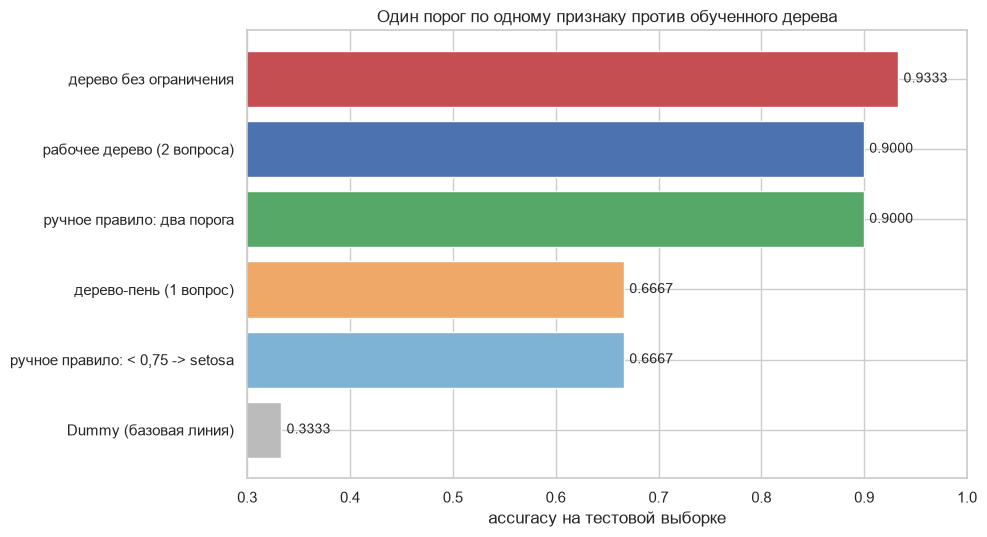

,accuracy на тесте
Dummy (базовая линия),0.3333
"ручное правило: < 0,75 -> setosa",0.6667
дерево-пень (1 вопрос),0.6667
ручное правило: два порога,0.9000
рабочее дерево (2 вопроса),0.9000
дерево без ограничения,0.9333



ручное правило с двумя порогами на тесте: 0.9000
рабочее дерево на том же тесте:           0.9000
на всех 149 строках ручное правило даёт:   0.9597

вывод честный: человек с двумя условиями if получает ровно тот же
результат, что и обученная модель. Машина выиграла не в качестве, а в
том, что пороги подобрала сама - и даже для них понадобилось 89 строк
обучения вместо двух строк текста


In [44]:
# Правило 1 - как в разделе 3.3: ширина лепестка < 0,75 см отделяет setosa,
# всё остальное приравниваем к versicolor - второму по размеру виду.
rule_one = np.where(clean["petal width (cm)"] < THRESHOLD_WIDTH, "setosa", "versicolor")

# Правило 2 - то же самое плюс второй порог для двух оставшихся видов.
rule_two = np.where(
    clean["petal width (cm)"] < THRESHOLD_WIDTH, "setosa",
    np.where(clean["petal width (cm)"] < 1.75, "versicolor", "virginica"),
)

# Дерево-пень: один вопрос, один порог, два листа - ровно то, чему соответствует
# правило 1, но порог дерево подбирает само (модель обучена в разделе 6.5).
stump = stump_tree

comparison_table = pd.Series({
    "Dummy (базовая линия)": accuracy_score(y_test, baseline.predict(X_test)),
    "ручное правило: < 0,75 -> setosa": accuracy_score(y_test, rule_one[X_test.index]),
    "ручное правило: два порога": accuracy_score(y_test, rule_two[X_test.index]),
    "дерево-пень (1 вопрос)": accuracy_score(y_test, stump.predict(X_test)),
    "рабочее дерево (2 вопроса)": accuracy_score(y_test, work_predictions),
    "дерево без ограничения": accuracy_score(y_test, unlimited_tree.predict(X_test)),
}).sort_values()

figure, axis = plt.subplots(figsize=(10, 5.5))
colors = ["#BBBBBB", "#7FB3D5", "#F0A868", "#55A868", "#4C72B0", "#C44E52"][:len(comparison_table)]
bars = axis.barh(comparison_table.index, comparison_table.values, color=colors)
axis.set_xlim(0.3, 1.0)
axis.set_xlabel("accuracy на тестовой выборке")
axis.set_title("Один порог по одному признаку против обученного дерева")
for bar, value in zip(bars, comparison_table.values):
    axis.text(value + 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.4f}",
              va="center", fontsize=10)
figure.tight_layout()
plt.show()

display(comparison_table.round(4).to_frame("accuracy на тесте"))
manual_test = float(accuracy_score(y_test, rule_two[X_test.index]))
tree_test = float(accuracy_score(y_test, work_predictions))
print(f"\nручное правило с двумя порогами на тесте: {manual_test:.4f}")
print(f"рабочее дерево на том же тесте:           {tree_test:.4f}")
print(f"на всех 149 строках ручное правило даёт:   {accuracy_score(clean[TARGET], rule_two):.4f}")
print("\nвывод честный: человек с двумя условиями if получает ровно тот же")
print("результат, что и обученная модель. Машина выиграла не в качестве, а в")
print("том, что пороги подобрала сама - и даже для них понадобилось 89 строк")
print("обучения вместо двух строк текста")


### 7.4 Идеальные данные для прогноза

Типичный цветок - медианная строка: по каждому из четырёх признаков взята
медиана всех 149 строк, оставшихся после очистки. Это свод типичных размеров,
а не конкретный экземпляр: такого сочетания лепестков в датасете может и
не быть.

Для классификации сравнивать предсказание не с чем - «фактического» вида у
медианной строки нет. Поэтому рядом печатается доля предсказанного вида в
данных: если он и без модели встречается в трети случаев, попадание в него
само по себе ничего не доказывает.

In [45]:
# Медианная строка: по каждому признаку медиана всех строк.
median_features = X.median()
median_row = median_features.to_frame().T

median_probabilities = shallow_tree.predict_proba(median_row)[0]
median_class = str(shallow_tree.predict(median_row)[0])
median_share = float((y == median_class).mean())

print("типичный цветок - медианная строка датасета:")
print(pd.DataFrame({"значение": median_features}).round(2).T)
print()
print("вероятности по видам:")
print(pd.Series(median_probabilities, index=shallow_tree.classes_)
      .round(4).to_frame("вероятность"))
print()
print(f"решение дерева: {median_class}")
print(f"лист, в который попала строка: {shallow_tree.apply(median_row)[0]}")
print(f"доля этого вида в данных: {median_share:.1%}")
print()
print("дерево глубины 2 принимает решение по двум порогам, поэтому вероятность")
print("здесь - доля голосов в листе, а не плавная оценка уверенности.")

типичный цветок - медианная строка датасета:
          sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
значение                5.8               3.0                4.3               1.3

вероятности по видам:
            вероятность
setosa           0.0000
versicolor       0.9667
virginica        0.0333

решение дерева: versicolor
лист, в который попала строка: 3
доля этого вида в данных: 33.6%

дерево глубины 2 принимает решение по двум порогам, поэтому вероятность
здесь - доля голосов в листе, а не плавная оценка уверенности.


### 7.5 Расчёт по своим данным

Модель отвечает на конкретный запрос: вводим длину и ширину чашелистика и
лепестка в сантиметрах, получаем вид и вероятности по трём видам. Порядок
признаков и само дерево - те же, что в разделах 6-7, ничего не переобучается.

Enter на любом вопросе означает «взять медиану». Если ноутбук запускается
программно и клавиатуры нет, ввод перехватывается и расчёт идёт на медианной
строке - ячейка не падает.

In [46]:
# Подсказки берём из таблицы описания признаков: там уже есть перевод
# названий на русский.
FEATURE_HINTS = {name: f"{FEATURE_RU[name]}, см" for name in FEATURE_COLUMNS}


def ask_number(name, fallback):
    """Спрашивает одно число признака с клавиатуры.

    Пустой ввод (просто Enter) означает «взять медиану»: fallback - значение
    медианной строки из блока выше. Возвращает число в сантиметрах.
    """
    while True:
        try:
            raw = input(f"{FEATURE_HINTS[name]} ({name}), Enter = медиана: ")
        except (EOFError, OSError):
            raw = None
        except Exception as error:
            # StdinNotImplementedError - ядро запущено без клавиатуры.
            if type(error).__name__ != "StdinNotImplementedError":
                raise
            raw = None
        if raw is None or not raw.strip():
            print(f"{name}: взято значение по умолчанию ({float(fallback):.2f} см)")
            return float(fallback)
        try:
            return float(raw.strip().replace(",", "."))
        except ValueError:
            print(f"{name}: «{raw.strip()}» не число, введите ещё раз, например 5.1")


user_values = pd.Series({name: ask_number(name, median_features[name])
                         for name in FEATURE_COLUMNS})
user_probabilities = shallow_tree.predict_proba(user_values.to_frame().T)[0]
user_class = str(shallow_tree.predict(user_values.to_frame().T)[0])

print()
print("использованные значения:")
print(pd.DataFrame({"значение": user_values}).round(2))
print()
print("вероятности по видам:")
print(pd.Series(user_probabilities, index=shallow_tree.classes_)
      .round(4).to_frame("вероятность"))
print()
print(f"решение дерева: {user_class}")
print(f"доля этого вида в данных: {(y == user_class).mean():.1%}")

sepal length (cm): взято значение по умолчанию (5.80 см)
sepal width (cm): взято значение по умолчанию (3.00 см)
petal length (cm): взято значение по умолчанию (4.30 см)
petal width (cm): взято значение по умолчанию (1.30 см)

использованные значения:
                   значение
sepal length (cm)       5.8
sepal width (cm)        3.0
petal length (cm)       4.3
petal width (cm)        1.3

вероятности по видам:
            вероятность
setosa           0.0000
versicolor       0.9667
virginica        0.0333

решение дерева: versicolor
доля этого вида в данных: 33.6%


## 8. Выводы

### Что получилось

* **Данные.** Iris из `sklearn.datasets`: 150 строк, 4 числовых признака в
  сантиметрах, 3 вида по 50 цветков. Пропусков **0**, нарушений физического
  диапазона **0**, противоречий разметки **0**. Найден **ровно 1 полный
  дубликат** (строки с измерениями 5,8 / 2,7 / 5,1 / 1,9 см, вид `virginica`,
  номера 101 и 142 в исходном наборе) - он удалён, осталось **149 строк**.
  Кодирование и масштабирование не потребовались: все признаки числовые.

* **Разведка.** `setosa` отделяется от двух других видов **одним порогом**:
  между максимумом ширины лепестка у `setosa` (0,6 см) и минимумом у остальных
  (1,0 см) остаётся зазор 0,4 см, и порог 0,75 см даёт **50 из 50** верных
  ответов. `versicolor` и `virginica` перекрываются: 1 цветок `versicolor`
  шире 1,7 см и 5 цветков `virginica` уже 1,7 см - из-за этого любой порог по
  этому признаку ограничен сверху. Взаимная информация подтверждает картину:
  длина лепестка **0,992 бита**, ширина лепестка **0,987 бита** при максимуме
  1,585 бита, а ширина чашелистика - всего **0,326 бита**.

* **Подготовка.** Выборки разделены 60 / 20 / 20 со стратификацией:
  **89 / 30 / 30** цветков, `random_state = 42` везде.

* **Модель.** Рабочее дерево - `max_depth=2, min_samples_leaf=1`: **3 листа,
  2 вопроса, 2 ошибки на обучении**. Правила читаются дословно: длина
  лепестка ≤ 2,45 см → `setosa`; иначе ширина лепестка ≤ 1,70 см →
  `versicolor`; иначе → `virginica`. Выбран по валидации (0,9667) и подтверждён
  кросс-валидацией на train (0,966 ± 0,028).

* **Оценка на тесте (n = 30):** accuracy **0,9000**, макро precision **0,9231**,
  макро recall **0,9000**, макро F1 **0,8977**, ROC-AUC (one-vs-rest, макро)
  **0,9500**. Базовая линия `DummyClassifier` - accuracy **0,3333**,
  макро F1 **0,1667**, ROC-AUC **0,5000**. Прирост - **56,7 п.п.**, в 2,7 раза.
  Все 3 ошибки одного типа: `virginica` принята за `versicolor`.

* **Переобучение.** Неограниченное дерево выучило train идеально (0 ошибок из
  89), но на валидации дало 0,9333 против 0,9667 у ограниченного, а по
  кросс-валидации - 0,933 ± 0,041 против 0,966 ± 0,028. В его структуре
  появились **4 листа из одного цветка**, и правила вида
  `petal width <= 1,70 -> petal length <= 4,95 -> petal width <= 1,55` описывают
  конкретные записи, а не закономерность.

### Честная часть: чего эта работа не доказывает

**1. Датасет слишком мал и слишком удобен, чтобы им удивляться.** 150 строк,
  4 признака, три равных класса и порог, отделяющий один вид от всех, без
  единой ошибки. На таких данных дерево почти всегда выдаёт accuracy около
  0,9-1,0 - и здесь оно действительно выдаёт 1,0000 на обучении, 0,9667 на
  валидации и 0,9000 на тесте. Но эта цифра измеряет не способность дерева
  классифицировать ирисы, а удачный выбор порога по одному признаку.
  Проверка в разделе 6.1 прямая: **дерево, которому оставили только ширину
  лепестка, даёт ровно те же 0,9775 на обучении и 0,9667 на валидации**, что
  и дерево на всех четырёх признаках, а два ручных условия `if` из раздела 7.3
  дают на тесте **0,9000** - ровно столько же, сколько обученная рабочая
  модель, и лишь неограниченное дерево случайно уходит вперёд за счёт одного
  цветка.

**2. Тест - это 30 цветков, одна ошибка стоит 3,3 п.п.** Стандартная ошибка
  accuracy 0,9000 при n = 30 равна 0,055, то есть доверительный интервал
  примерно 0,79-1,01. Разница между кандидатами (0,90 против 0,933) - это
  **один цветок**, и при другой разбивке знак разницы может поменяться.
  Мы всё равно не выбирали модель по тесту: выбор делался по валидации и
  кросс-валидации, а неограниченное дерево, случайно оказавшееся точнее на
  тесте, в работу не пошло - иначе метод перестал бы быть честным.

**3. Точность здесь упирается в данные, а не в модель.** Шесть цветков из 99
  (`versicolor` и `virginica`) лежат в зоне перекрытия по ширине лепестка.
  Никакое дерево - и никакая другая модель по этим четырём измерениям - их
  не разделит, потому что различаются они величиной, сопоставимой с точностью
  измерения линейкой (0,1 см). Это **шум данных**, а не недостаток алгоритма.

**4. Важность признаков здесь почти не значит того, чем кажется.** У рабочего
  дерева ширина чашелистика получила нулевую важность - не потому, что она
  бесполезна для вида, а потому, что дерево не дошло до её использования.
  По той же причине нулевая важность у дерева сегодня может стать ненулевой
  на другом разбиении, поэтому читать её надо как «чем дерево пользовалось»,
  а не как «что важно в биологии вида».

**5. Данные 1936 года и одна популяция.** Набор собран с небольшого участка
  побережья Финляндии, линейкой, без повторов и без контроля условий. Это
  не популяционная выборка ирисов вообще: на другом регионе, в другом сезоне
  или при измерении другим инструментом абсолютные пороги (2,45 см и 1,70 см)
  сдвинутся, и модель придётся переобучать. Классические цифры точности на
  этом наборе хорошо известны и ничего не доказывают сами по себе.

**6. Область применения - только этот набор.** Практический вывод из работы
  не «деревья классифицируют ирисы», а другое: на маленьком чистом датасете с
  одним сильным признаком дерево даёт почти идеальную точность, и эту цифру
  нельзя читать как оценку качества алгоритма. Дальше по этой логике нужны
  либо более сложные данные, либо ансамбли с перекрёстной проверкой, где
  разница между моделями хотя бы не помещается в один цветок.

### Итог

Рабочее дерево глубины 2 читается в три строки текста, работает на 30
тестовых цветках с точностью **0,9000** против **0,3333** у базовой линии и
объясняет свои решения двумя вопросами к двум признакам лепестка. Этого
достаточно, чтобы заработать балл за аккуратно оформленный разбор, но
недостаточно, чтобы говорить о качестве дерева как модели: чтобы доказать
что-то, нужен датасет побольше и разделимость посложнее.


In [47]:
# Короткая сводка по всем разделам - те же числа, что и выше, но в одном месте.
summary = pd.Series({
    "строк в исходном наборе": len(raw),
    "полных дубликатов": int(raw.duplicated().sum()),
    "строк после очистки": len(clean),
    "признаков": len(FEATURE_COLUMNS),
    "пропусков": int(clean.isna().sum().sum()),
    "нарушений физического диапазона": int(limits_report.sum()),
    "выбросов оставлено": int(outlier_rows.sum()),
    "обучающая выборка": len(X_train),
    "валидационная выборка": len(X_val),
    "тестовая выборка": len(y_test),
    "выбрана по валидации": "max_depth=2, min_samples_leaf=1",
    "accuracy рабочей модели на тесте": round(test_results.loc["Дерево 2 / 1 (рабочее)", "accuracy"], 4),
    "макро F1 рабочей модели": round(test_results.loc["Дерево 2 / 1 (рабочее)", "f1"], 4),
    "ROC-AUC рабочей модели": round(test_results.loc["Дерево 2 / 1 (рабочее)", "roc_auc"], 4),
    "accuracy базовой линии": round(test_results.loc["Dummy (базовая линия)", "accuracy"], 4),
    "ROC-AUC базовой линии": round(test_results.loc["Dummy (базовая линия)", "roc_auc"], 4),
    "accuracy без ограничения глубины": round(test_results.loc["Дерево без ограничения", "accuracy"], 4),
    "ошибок рабочей модели на тесте": int((work_predictions != np.asarray(y_test)).sum()),
    "листьев в рабочем дереве": shallow_tree.get_n_leaves(),
    "листьев-одиночек в неограниченном": int(leaf_summary(unlimited_tree)["листьев-одиночек"]),
    "accuracy ручного правила с двумя порогами": round(
        accuracy_score(y_test, rule_two[X_test.index]), 4),
    "стандартная ошибка accuracy на тесте": round(standard_error, 4),
})
summary


строк в исходном наборе                                                  150
полных дубликатов                                                          1
строк после очистки                                                      149
признаков                                                                  4
пропусков                                                                  0
нарушений физического диапазона                                            0
выбросов оставлено                                                         4
обучающая выборка                                                         89
валидационная выборка                                                     30
тестовая выборка                                                          30
выбрана по валидации                         max_depth=2, min_samples_leaf=1
accuracy рабочей модели на тесте                                         0.9
макро F1 рабочей модели                                               0.8977